# Модель предсказания возраста посетителей сайтов 
- Автор: Макарова Елизавета Алексеевна
- Дата: 31.07.2026
---

## Введение
### Цель проекта и постановка задачи машинного обучения
**Цель:** разработать модель машинного обучения, которая по данным о поведении анонимного пользователя в цифровой среде для определения его примерного возраста, чтобы бизнес мог целесообразно распределять рекламу на целевую аудиторию определенного возраста, что позволит снизить риски показа рекламы для взрослых совершеннолетним.

### Постановка задач машинного обучения
1. Собрать датафреймы в единую витрину данных для возможности построения модели с максимальным набором признаков;
2. Обработать данные: провести анализ дубликатов, пропусков, изучить и откорректировать выбросы;
3. Обучить и сравнить дамми модель, модель логистической регрессиии и опорных векторов с разными ядрыми;
4. Сравнить модели по метрикам: основная метрика проверки качества - `F1-мера`, вспомогательные метрики качества: `precision` и `recall`;
5. Подготовить финальную модель ко внедрению.

### Описание данных
**Таблица `users`**

Таблица содержит данные о пользователях.  
- `user_id` - уникальный идентификатор пользователя.
- `age_category` - возрастная категория пользователя, *целевая переменная*. 

**Таблица `visits`**  

Содержит информацию об активности пользователей на разных сайтах.  
- `date` — дата посещения сайта.
- `daytime` — анонимизированное время посещения сайта. Категории: утро, день, вечер, ночь.
- `session_id` — уникальный идентификатор сессии.
- `user_id` — уникальный идентификатор пользователя.
- `website_category` — анонимизированная категория сайта.

**Таблица `ads_activity`**  

Активность взаимодействия пользователя с рекламными объявлениями связана с возрастом.  
- `user_id` — уникальный идентификатор пользователя.
- `ads_activity` — характеристика CTR, выраженная одним из значений: очень редко, редко, умеренно, часто, очень часто.

**Таблица `surf_depth`**  

В таблице содержится информация о глубине перехода пользователя по сайтам во время одной сессии.  
- `user_id` — уникальный идентификатор пользователя.
- `surf_depth` — категориальная переменная, характеризующая глубину перехода: поверхностно, средне, глубоко.

**Таблица `primary_device`**  

Таблица содержит информацию об основном устройстве пользователя для выхода в интернет. 
- `user_id` — уникальный идентификатор пользователя.
- `primary_device` — тип основного устройства пользователя.

**Таблица `cloud_usage`**  

Использование облачных технологий также может быть связано с возрастной категорией пользователя.  
- `user_id` — уникальный идентификатор пользователя.
- `cloud_usage` — признак использования облачных ресурсов. `True` означает, что пользователь обращается к облачным ресурсам типа Яндекс 360.
---

## Подготовка среды и библиотек
Для начала установим и настроем необходимые версии библиотек:

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn phik joblib missingno

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import phik
import warnings
import joblib
import missingno as msno
import scipy
import os

from itertools import product
from scipy.stats import mstats
from IPython.display import FileLink
from pandas.api.types import is_float_dtype
from time import time        

from phik.phik import phik_matrix

from sklearn.metrics import (
    make_scorer,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,  
    log_loss,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    classification_report,
    auc,
    ConfusionMatrixDisplay, 
    brier_score_loss
)

from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.preprocessing import RobustScaler, StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import TransformerMixin, BaseEstimator
from sklearn.compose import make_column_selector
from sklearn.calibration import (
    CalibratedClassifierCV, 
    calibration_curve, 
    CalibrationDisplay
)
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif, RFE, RFECV, SelectKBest, SequentialFeatureSelector as SFS
from sklearn.frozen import FrozenEstimator
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 15)
np.random.seed(42)

Зафиксируем версии пакетов в `requirements.txt`:

In [3]:
!pip freeze > requirements.txt

### Загрузка датасетов

In [4]:
users_df = pd.read_csv('datasets/ds_s13_users.csv', decimal=',')
visits_df = pd.read_csv('datasets/ds_s13_visits.csv', decimal=',')
ads_df = pd.read_csv('datasets/ads_activity.csv', decimal=',')
surf_depth_df = pd.read_csv('datasets/surf_depth.csv', decimal=',')
device_df = pd.read_csv('datasets/primary_device.csv', decimal=',')
cloud_df = pd.read_csv('datasets/cloud_usage.csv', decimal=',')

In [5]:
users_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5913 entries, 0 to 5912
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   user_id       5913 non-null   str  
 1   age_category  5913 non-null   int64
dtypes: int64(1), str(1)
memory usage: 92.5 KB


In [6]:
visits_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1065745 entries, 0 to 1065744
Data columns (total 5 columns):
 #   Column            Non-Null Count    Dtype
---  ------            --------------    -----
 0   date              1065745 non-null  str  
 1   daytime           1065745 non-null  str  
 2   session_id        1065745 non-null  str  
 3   user_id           1065745 non-null  str  
 4   website_category  1065745 non-null  str  
dtypes: str(5)
memory usage: 40.7 MB


In [7]:
ads_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5826 entries, 0 to 5825
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   user_id       5826 non-null   str  
 1   ads_activity  5826 non-null   str  
dtypes: str(2)
memory usage: 91.2 KB


In [8]:
surf_depth_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5715 entries, 0 to 5714
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     5715 non-null   str  
 1   surf_depth  5715 non-null   str  
dtypes: str(2)
memory usage: 89.4 KB


In [9]:
device_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5669 entries, 0 to 5668
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   user_id         5669 non-null   str  
 1   primary_device  5669 non-null   str  
dtypes: str(2)
memory usage: 88.7 KB


In [10]:
cloud_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5680 entries, 0 to 5679
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   user_id      5680 non-null   str  
 1   cloud_usage  5680 non-null   bool 
dtypes: bool(1), str(1)
memory usage: 50.1 KB


### Выводы
Датасет содержит 6 таблиц с информацией о поведении пользователей в интернете. Основная таблица `visits_df` содержит 1065745 записей о посещениях сайтов и показах рекламы соответственно. Таблица `users_df` содержит информацию о 5913 пользователях и их возрастных категориях (целевая переменная `age_category`). Дополнительные таблицы `surf_depth_df`, `device_df` и `cloud_df`, `ads_df` содержат информацию о глубине просмотра, используемых устройствах и использовании облачных сервисов (5600-5700 записей).

1. **Типы данных:**
    - Большинство признаков имеют строковый тип данных, хотя некоторые содержат числовые значения (`date`, `daytime`, `session_id`, `user_id`, `surf_depth`)
    - Целевая переменная `age_category` уже имеет числовой тип `int64`
    - Признак `cloud_usage` имеет логический тип bool
    - Требуется преобразование: числовые колонки перевести в корректный тип (int/float), категориальные - в category для экономии памяти
    - Так же необходимо окорректировать разрядность для более удобной работы с данными

2. **Пропуски в данных:**
Все таблицы не содержат пропусков, что является преимуществом и не требует дополнительной обработки пропущенных значений. Требуется проанализировать это подробнее в ИАД, потому что пропуски могут быть уже заполнены выделяющимися значениями, что будет отображать крупные выбросы.

3. **Названия столбцов:**
Названия столбцов корректны, используют нижний регистр и знак подчеркивания, не требуют дополнительной обработки.

---

## Первичная предобработка данных
### Первичный анализ и очистка исходных датасетов

Проверим каждый датасет на наличие полных дубликатов строк и дубликатов по ключевому полю `user_id`.

In [11]:
datasets = {
    'visits_df': visits_df,
    'users_df': users_df,
    'ads_df': ads_df,
    'surf_depth_df': surf_depth_df,
    'device_df': device_df,
    'cloud_df': cloud_df
}

stats_list = []

for name, df in datasets.items():
    total_rows = len(df)
    unique_users = df['user_id'].nunique()
    full_dups = df.duplicated().sum()
    user_dups = df['user_id'].duplicated().sum() if 'user_id' in df.columns else 0
    
    stats_list.append({
        'Датасет': name,
        'Всего строк': total_rows,
        'Уникальных пользователей': unique_users,
        'Полных дубликатов строк': full_dups,
        'Дубликатов user_id': user_dups
    })

stats_df = pd.DataFrame(stats_list).set_index('Датасет')
stats_df

,Всего строк,Уникальных пользователей,Полных дубликатов строк,Дубликатов user_id
Датасет,,,,
visits_df,1065745,5826,15750,1059919
users_df,5913,5826,87,87
ads_df,5826,5593,233,233
surf_depth_df,5715,5715,0,0
device_df,5669,5669,0,0
cloud_df,5680,5680,0,0


В датафреймах присутствуют дубликаты:
- **visits_df**: целых 15750 полных дубликатов, скорее всего это ошибки в сборах логов, нужно удалить. А так же 1059919 дубликатов по `user_id`. Эти дубликаты являются нормальными, потому что в этом датафрейме содержится информация о посещениях пользователя и каждое посещение отображается новой строкой с его идентификатором.
- **users_df**: присутствуют 87 полных дубликатов, удаляем.
- **ads_df**: 233 полных дубликатов, тоже удаляем.

In [12]:
initial_visits = len(visits_df)
initial_users = len(users_df)
initial_ads = len(ads_df)

visits_df = visits_df.drop_duplicates()
users_df = users_df.drop_duplicates()
ads_df = ads_df.drop_duplicates()

print(f"visits_df: удалено {initial_visits - len(visits_df)} полных дубликатов")
print(f"users_df: удалено {initial_users - len(users_df)} полных дубликатов")
print(f"ads_df: удалено {initial_ads - len(ads_df)} полных дубликатов")

visits_df: удалено 15750 полных дубликатов
users_df: удалено 87 полных дубликатов
ads_df: удалено 233 полных дубликатов


### Объединение таблиц
При простом объединении при декартовом произведении количество строк будет огромным, больше 100млн, требуется агрегация крупных датафреймов перед объединением с главным `users_df`.

In [13]:
site_counts = pd.crosstab(visits_df['user_id'],
                          visits_df['website_category'],
                         normalize='index').round(3)

site_counts.columns = [
    f'site_share_{column.replace(" ", "_").lower()}'
    for column in site_counts.columns
]

site_counts = site_counts.reset_index()

# Агрегация visits_df
visits_agg = visits_df.groupby('user_id').agg(
    total_visits=('session_id', 'count'),
    unique_sessions=('session_id', 'nunique'),
    unique_days_active=('date', 'nunique'),
    unique_site_categories=('website_category', 'nunique'),
    morning_visits=('daytime', lambda x: (x == 'утро').sum()),
    day_visits=('daytime', lambda x: (x == 'день').sum()),
    evening_visits=('daytime', lambda x: (x == 'вечер').sum()),
    night_visits=('daytime', lambda x: (x == 'ночь').sum())
).reset_index()

# Объединение таблиц
df = users_df.copy()
df = df.merge(ads_df, on='user_id', how='left')
df = df.merge(surf_depth_df, on='user_id', how='left')
df = df.merge(device_df, on='user_id', how='left')
df = df.merge(cloud_df, on='user_id', how='left')
df = df.merge(visits_agg, on='user_id', how='left')
df = df.merge(site_counts, on='user_id', how='left')

print(f"Итоговый размер: {df.shape[0]} строк, {df.shape[1]} столбцов")

Итоговый размер: 5826 строк, 34 столбцов


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5826 entries, 0 to 5825
Data columns (total 34 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   user_id                 5826 non-null   str    
 1   age_category            5826 non-null   int64  
 2   ads_activity            5593 non-null   str    
 3   surf_depth              5715 non-null   str    
 4   primary_device          5669 non-null   str    
 5   cloud_usage             5680 non-null   object 
 6   total_visits            5826 non-null   int64  
 7   unique_sessions         5826 non-null   int64  
 8   unique_days_active      5826 non-null   int64  
 9   unique_site_categories  5826 non-null   int64  
 10  morning_visits          5826 non-null   int64  
 11  day_visits              5826 non-null   int64  
 12  evening_visits          5826 non-null   int64  
 13  night_visits            5826 non-null   int64  
 14  site_share_category_01  5826 non-null   float64
 15

In [15]:
df.head()

,user_id,age_category,ads_activity,surf_depth,primary_device,cloud_usage,total_visits,unique_sessions,unique_days_active,unique_site_categories,morning_visits,day_visits,evening_visits,night_visits,site_share_category_01,site_share_category_02,site_share_category_03,site_share_category_04,site_share_category_05,site_share_category_06,site_share_category_07,site_share_category_08,site_share_category_09,site_share_category_10,site_share_category_11,site_share_category_12,site_share_category_13,site_share_category_14,site_share_category_15,site_share_category_16,site_share_category_17,site_share_category_18,site_share_category_19,site_share_category_20
0,f545-8c95aefe8d3e5548a689-a5b2fd39,4,NaN,глубоко,смартфон,False,187,187,14,19,43,67,63,14,0.064,0.037,0.037,0.059,0.102,0.021,0.000,0.048,0.102,0.027,0.075,0.016,0.032,0.037,0.053,0.043,0.059,0.070,0.075,0.043
1,cb48-5a0d6cde4d86ae10637e-c8ceb6ed,2,умеренно,средне,смартфон,False,141,141,14,19,25,48,55,13,0.064,0.043,0.099,0.021,0.057,0.035,0.106,0.106,0.043,0.071,0.043,0.043,0.035,0.000,0.064,0.035,0.035,0.028,0.035,0.035
2,678b-614cd47d854b9d591db2-000b2e50,0,умеренно,средне,смартфон,False,100,100,14,17,20,29,38,13,0.010,0.070,0.000,0.110,0.070,0.130,0.000,0.040,0.000,0.010,0.030,0.150,0.120,0.010,0.020,0.030,0.020,0.010,0.110,0.060
3,4ac0-dad169100b4a29b20818-b26ae7c5,4,редко,поверхностно,смартфон,True,248,248,14,19,57,109,64,18,0.081,0.004,0.101,0.028,0.109,0.048,0.028,0.065,0.060,0.000,0.065,0.016,0.077,0.020,0.024,0.028,0.065,0.133,0.036,0.012
4,f19b-9ac21ca973b41ecfa8c3-6a58191d,0,очень редко,поверхностно,смартфон,True,119,119,14,19,19,41,50,9,0.067,0.042,0.092,0.034,0.050,0.008,0.050,0.067,0.076,0.042,0.042,0.126,0.000,0.084,0.025,0.025,0.050,0.034,0.025,0.059


**Выводы:**
После слияния таблиц получилась компактная таблица на 6146 пользователей и 33 столбца.
- **Пропуски:** в столбцах `ads_activity`, `surf_depth`, `primary_device`, `cloud_usage` появились пропуски, их количество составляет примерно от 2 до 4 процентов, что вполне нормально.
- **Типы данных:** числовые значения хранятся в типе `int64` и `float64`, что требует оптимизации для ускорения обучения моделей, а строковые признаки нужно превратить в `category`.

### Работа с типами данных

In [16]:
""" 
    Посмотрим количество уникальных значений в столбцах, чтобы понять, 
    какие стоит приводить к категориальному типу данных:
"""

for col in df.columns:
    print(f'{str(df[col].dtype):<6} - {col}: {df[col].nunique()}')

str    - user_id: 5826
int64  - age_category: 5
str    - ads_activity: 5
str    - surf_depth: 3
str    - primary_device: 4
object - cloud_usage: 2
int64  - total_visits: 366
int64  - unique_sessions: 366
int64  - unique_days_active: 2
int64  - unique_site_categories: 6
int64  - morning_visits: 119
int64  - day_visits: 177
int64  - evening_visits: 178
int64  - night_visits: 59
float64 - site_share_category_01: 157
float64 - site_share_category_02: 146
float64 - site_share_category_03: 231
float64 - site_share_category_04: 151
float64 - site_share_category_05: 159
float64 - site_share_category_06: 150
float64 - site_share_category_07: 150
float64 - site_share_category_08: 167
float64 - site_share_category_09: 151
float64 - site_share_category_10: 161
float64 - site_share_category_11: 139
float64 - site_share_category_12: 150
float64 - site_share_category_13: 245
float64 - site_share_category_14: 148
float64 - site_share_category_15: 150
float64 - site_share_category_16: 146
float64 - sit

In [17]:
df.head()

,user_id,age_category,ads_activity,surf_depth,primary_device,cloud_usage,total_visits,unique_sessions,unique_days_active,unique_site_categories,morning_visits,day_visits,evening_visits,night_visits,site_share_category_01,site_share_category_02,site_share_category_03,site_share_category_04,site_share_category_05,site_share_category_06,site_share_category_07,site_share_category_08,site_share_category_09,site_share_category_10,site_share_category_11,site_share_category_12,site_share_category_13,site_share_category_14,site_share_category_15,site_share_category_16,site_share_category_17,site_share_category_18,site_share_category_19,site_share_category_20
0,f545-8c95aefe8d3e5548a689-a5b2fd39,4,NaN,глубоко,смартфон,False,187,187,14,19,43,67,63,14,0.064,0.037,0.037,0.059,0.102,0.021,0.000,0.048,0.102,0.027,0.075,0.016,0.032,0.037,0.053,0.043,0.059,0.070,0.075,0.043
1,cb48-5a0d6cde4d86ae10637e-c8ceb6ed,2,умеренно,средне,смартфон,False,141,141,14,19,25,48,55,13,0.064,0.043,0.099,0.021,0.057,0.035,0.106,0.106,0.043,0.071,0.043,0.043,0.035,0.000,0.064,0.035,0.035,0.028,0.035,0.035
2,678b-614cd47d854b9d591db2-000b2e50,0,умеренно,средне,смартфон,False,100,100,14,17,20,29,38,13,0.010,0.070,0.000,0.110,0.070,0.130,0.000,0.040,0.000,0.010,0.030,0.150,0.120,0.010,0.020,0.030,0.020,0.010,0.110,0.060
3,4ac0-dad169100b4a29b20818-b26ae7c5,4,редко,поверхностно,смартфон,True,248,248,14,19,57,109,64,18,0.081,0.004,0.101,0.028,0.109,0.048,0.028,0.065,0.060,0.000,0.065,0.016,0.077,0.020,0.024,0.028,0.065,0.133,0.036,0.012
4,f19b-9ac21ca973b41ecfa8c3-6a58191d,0,очень редко,поверхностно,смартфон,True,119,119,14,19,19,41,50,9,0.067,0.042,0.092,0.034,0.050,0.008,0.050,0.067,0.076,0.042,0.042,0.126,0.000,0.084,0.025,0.025,0.050,0.034,0.025,0.059


**Из этого можно сделать выводы:**

Целевая переменная - `age_category`,
- Числовые дискретные признаки: `total_visits`, `unique_sessions`, `unique_days_active`, `unique_site_categories`
- Числовые: признаки времени суток и категорий сайтов
- Категориальные:  `ads_activity`, `surf_depth`, `primary_device`
- Бинарные: `cloud_usage`
- Признак `user_id` бесполезен, модель просто запомнит некоторые значения, что приведет к шуму. Он будет удален.

Категориальные признаки имеют небольшое количество категорий, поэтому на предобработке данных перед обучением модели будем использовать `One-Hot-Encoding`. Масштабировать признаки будем в зависимости от выбросов, что будет рассмотрено в ИАД.

**Напишем функцию для удобного преобразования типов данных:**

In [18]:
def optimization(df, cols, dtype):
    for col in cols:
        if col in df.columns:
            df[col] = df[col].astype(dtype)
            
            if is_float_dtype(df[col]):
                df[col] = pd.to_numeric(df[col], downcast='float')
    return df

In [19]:
target_col = 'age_category'

numeric_float_cols = [
    col for col in df.columns if df[col].dtype == 'float64'
]

numeric_int_cols = [
    col for col in df.columns if df[col].dtype == 'int64'
]

categorical_cols = [
    'ads_activity', 'surf_depth', 'primary_device'
]

binary_cols = ['cloud_usage']

In [20]:
optimization(df, numeric_float_cols, 'Float64')
optimization(df, numeric_int_cols, 'Int16')
optimization(df, categorical_cols, 'category')
optimization(df, target_col, 'Int8')
optimization(df, binary_cols, 'Int8')

,user_id,age_category,ads_activity,surf_depth,primary_device,cloud_usage,total_visits,unique_sessions,unique_days_active,unique_site_categories,morning_visits,day_visits,evening_visits,night_visits,site_share_category_01,site_share_category_02,site_share_category_03,site_share_category_04,site_share_category_05,site_share_category_06,site_share_category_07,site_share_category_08,site_share_category_09,site_share_category_10,site_share_category_11,site_share_category_12,site_share_category_13,site_share_category_14,site_share_category_15,site_share_category_16,site_share_category_17,site_share_category_18,site_share_category_19,site_share_category_20
0,f545-8c95aefe8d3e5548a689-a5b2fd39,4,NaN,глубоко,смартфон,0,187,187,14,19,43,67,63,14,0.064000003039837,0.037000000476837,0.037000000476837,0.059000000357628,0.101999998092651,0.020999999716878,0.0,0.048000000417233,0.101999998092651,0.027000000700355,0.075000002980232,0.016000000759959,0.032000001519918,0.037000000476837,0.052999999374151,0.043000001460314,0.059000000357628,0.070000000298023,0.075000002980232,0.043000001460314
1,cb48-5a0d6cde4d86ae10637e-c8ceb6ed,2,умеренно,средне,смартфон,0,141,141,14,19,25,48,55,13,0.064000003039837,0.043000001460314,0.098999999463558,0.020999999716878,0.057000000029802,0.035000000149012,0.105999998748302,0.105999998748302,0.043000001460314,0.071000002324581,0.043000001460314,0.043000001460314,0.035000000149012,0.0,0.064000003039837,0.035000000149012,0.035000000149012,0.028000000864267,0.035000000149012,0.035000000149012
2,678b-614cd47d854b9d591db2-000b2e50,0,умеренно,средне,смартфон,0,100,100,14,17,20,29,38,13,0.009999999776483,0.070000000298023,0.0,0.109999999403954,0.070000000298023,0.129999995231628,0.0,0.03999999910593,0.0,0.009999999776483,0.029999999329448,0.150000005960464,0.119999997317791,0.009999999776483,0.019999999552965,0.029999999329448,0.019999999552965,0.009999999776483,0.109999999403954,0.059999998658895
3,4ac0-dad169100b4a29b20818-b26ae7c5,4,редко,поверхностно,смартфон,1,248,248,14,19,57,109,64,18,0.081000000238419,0.00400000018999,0.101000003516674,0.028000000864267,0.108999997377396,0.048000000417233,0.028000000864267,0.064999997615814,0.059999998658895,0.0,0.064999997615814,0.016000000759959,0.076999999582767,0.019999999552965,0.024000000208616,0.028000000864267,0.064999997615814,0.133000001311302,0.035999998450279,0.012000000104308
4,f19b-9ac21ca973b41ecfa8c3-6a58191d,0,очень редко,поверхностно,смартфон,1,119,119,14,19,19,41,50,9,0.06700000166893,0.041999999433756,0.092000000178814,0.034000001847744,0.050000000745058,0.00800000037998,0.050000000745058,0.06700000166893,0.07599999755621,0.041999999433756,0.041999999433756,0.126000002026558,0.0,0.083999998867512,0.025000000372529,0.025000000372529,0.050000000745058,0.034000001847744,0.025000000372529,0.059000000357628
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5821,f4bd-a23c0f510067ac3836b6-052bd910,0,умеренно,средне,планшет,1,213,213,14,19,43,72,75,23,0.089000001549721,0.046999998390675,0.032999999821186,0.061000000685453,0.075000002980232,0.037999998778105,0.023000000044703,0.056000001728535,0.037999998778105,0.075000002980232,0.037999998778105,0.041999999433756,0.0,0.070000000298023,0.028000000864267,0.00899999961257,0.070000000298023,0.075000002980232,0.08500000089407,0.046999998390675
5822,eda0-e3e82537c708854dd5f2-ec0540bf,3,редко,глубоко,смартфон,0,160,160,14,19,29,63,60,8,0.056000001728535,0.018999999389052,0.061999998986721,0.043999999761581,0.068999998271465,0.093999996781349,0.018999999389052,0.0,0.050000000745058,0.075000002980232,0.025000000372529,0.025000000372529,0.075000002980232,0.030999999493361,0.087999999523163,0.087999999523163,0.012000000104308,0.061999998986721,0.075000002980232,0.030999999493361
5823,e0d8-1b36a6b475ebfbf87c14-fa566d97,0,редко,поверхностно,планшет,1,253,253,14,19,37,82,109,25,0.054999999701977,0.019999999552965,0.071000002324581,0.07500000

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5826 entries, 0 to 5825
Data columns (total 34 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   user_id                 5826 non-null   str     
 1   age_category            5826 non-null   Int16   
 2   ads_activity            5593 non-null   category
 3   surf_depth              5715 non-null   category
 4   primary_device          5669 non-null   category
 5   cloud_usage             5680 non-null   Int8    
 6   total_visits            5826 non-null   Int16   
 7   unique_sessions         5826 non-null   Int16   
 8   unique_days_active      5826 non-null   Int16   
 9   unique_site_categories  5826 non-null   Int16   
 10  morning_visits          5826 non-null   Int16   
 11  day_visits              5826 non-null   Int16   
 12  evening_visits          5826 non-null   Int16   
 13  night_visits            5826 non-null   Int16   
 14  site_share_category_01  5826 non-nu

Успешно изменены и оптимизированы типы данных, теперь они соответствуют содержимому.

In [22]:
temp = df.copy()

### Проверка на наличие явных и неявных дубликатов
Нормализация строковых типов данных не требуется.

**Изучение явных дубликатов:**

In [23]:
print(f"Количество полных дубликатов в датафрейме: {df.duplicated().sum()}")

Количество полных дубликатов в датафрейме: 0


Дубликаты отсутствуют.

In [24]:
print(f"Количество строк до удаления дубликатов: {df.shape[0]}")
df = df.drop_duplicates()
print(f"Количество строк после удаления дубликатов: {df.shape[0]}")

Количество строк до удаления дубликатов: 5826
Количество строк после удаления дубликатов: 5826


**Изучение неявных дубликатов:**

Дубликаты по идентификатору пользователя:

In [25]:
print(f'Количество дубликатов по user_id: {df['user_id'].duplicated().sum()}')

Количество дубликатов по user_id: 0


**Выводы:**

Дубликаты не найдены. Очистка датасета перед объединением датафреймов помогла избежать их появления.

### Выводы по первичной предобработке данных
1. Успешно объединены 6 таблиц в единый датасет. **Текущий размер: 6146 строк, 34 столбца.**
 
    Для таблицы `visits_df` с большим количеством записей применена агрегация по `user_id` с созданием признаков:
    - `total_visits` — общее количество посещений
    - `unique_sessions` — количество уникальных сессий
    - `unique_days_active` — количество дней активности
    - `unique_site_categories` — количество уникальных категорий сайтов
    - Признаки, отвечающие за подсчет количества посищений в определенное время суток
    - Признаки, распределяющие количество посещений сайтов по категориям в долях.
      
2. **Оптимизация типов данных**
    - Категориальные признаки преобразованы в тип `category`
    - Числовые дискретные преобразованы из `int64` в `Int16` для экономии памяти.
    - Числовые признаки преобразованы в `Int16` и `Float32`
    - Целевая переменная и бинарный признак оптимизированы в `Int8`
      
4. **Удаление дубликатов:**
   Перед объединением таблиц в единый датафрейм таблицы были очищены от полных дубликатов. Дубликаты были найдены в таблицах `visits_df`, `users_df` и `ads_df`. Итоговый датафрейм дубликатов уже не содержал.

---

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5826 entries, 0 to 5825
Data columns (total 34 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   user_id                 5826 non-null   str     
 1   age_category            5826 non-null   Int16   
 2   ads_activity            5593 non-null   category
 3   surf_depth              5715 non-null   category
 4   primary_device          5669 non-null   category
 5   cloud_usage             5680 non-null   Int8    
 6   total_visits            5826 non-null   Int16   
 7   unique_sessions         5826 non-null   Int16   
 8   unique_days_active      5826 non-null   Int16   
 9   unique_site_categories  5826 non-null   Int16   
 10  morning_visits          5826 non-null   Int16   
 11  day_visits              5826 non-null   Int16   
 12  evening_visits          5826 non-null   Int16   
 13  night_visits            5826 non-null   Int16   
 14  site_share_category_01  5826 non-nu

## Исследовательский анализ данных (EDA)
### Анализ распределения целевой переменной

In [27]:
print(f"Целевая переменная: {df['age_category'].value_counts()}")

Целевая переменная: age_category
4    1766
2    1439
3    1254
0     853
1     514
Name: count, dtype: Int64


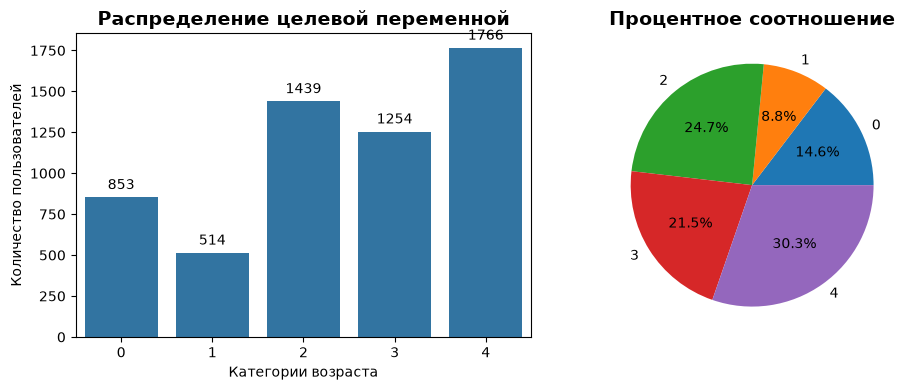

In [28]:
plt.figure(figsize=(10,4))

age_counts = df['age_category'].value_counts().sort_index()
plt.subplot(1,2,1)
sns.barplot(x=age_counts.index, y=age_counts.values)
plt.title('Распределение целевой переменной', fontsize=14, fontweight='bold')
plt.xlabel('Категории возраста')
plt.ylabel('Количество пользователей')

for i, v in enumerate(age_counts):
    plt.text(i, v+50, str(v), ha='center')

plt.subplot(1,2,2)
plt.pie(age_counts, autopct='%1.1f%%', labels=age_counts.index)
plt.title('Процентное соотношение', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

#### Результаты:
| Класс | Количество | Процент (%) |
| --- | --- | --- |
| 0 | 8546 | 14.6 |
| 1 | 514 | 8.8 |
| 2 | 1439 | 24.7 |
| 3 | 1254 | 21.5 |
| 4 | 1766 | 30.3 |

**Распределение классов неравномерное:**
- Наибольшую долю составляет категория 4, наименьшую - категория 1. Соотношение максимального к минимальному: ~3.5, что является умеренным дисбалансом.
- Категории 2, 3, 4 составляют ~75 процентов выборки. Предположительно, это возрастные группы. Категории 0 и 1 (молодые) представлены значительно реже.

**Выводы:**
1. Рекомендуемые метрики для оценки: `F1-weighted`, `F1-macro`
2. При обучении необходимо использовать стратифицированную кросс-валидацию (StratifiedKFold).

# Анализ признаков

In [29]:
target_col = 'age_category'

features_df = df.drop(columns=[target_col])

num_cols = features_df.select_dtypes(
    include=['Int8', 'Int16', 'Float32']
).columns.tolist()

cat_cols = features_df.select_dtypes(
    include=['category']
).columns.tolist()

In [30]:
importance_data = []

print(f"Числовые признаки: {num_cols}")
print(f"Категориальные признаки: {cat_cols}\n")

for col in num_cols:
    medians = {}
    for age in sorted(df['age_category'].unique()):
        medians[age] = df.loc[df['age_category'] == age, col].median()
    
    min_med = min(medians.values())
    max_med = max(medians.values())
    
    if min_med != 0:
        diff = (max_med - min_med) / min_med * 100
    else:
        diff = max_med * 100 
    
    importance_data.append({
        'Признак': col,
        'Тип': 'Числовой',
        'Медиана (кат. 0)': round(medians.get(0, 0), 2),
        'Медиана (кат. 1)': round(medians.get(1, 0), 2),
        'Медиана (кат. 2)': round(medians.get(2, 0), 2),
        'Медиана (кат. 3)': round(medians.get(3, 0), 2),
        'Медиана (кат. 4)': round(medians.get(4, 0), 2),
        'Разброс, %': round(diff, 2)
    })

for col in cat_cols:
    age_means = df.groupby(col, observed=True)['age_category'].mean()
    
    min_mean = age_means.min()
    max_mean = age_means.max()
    
    if min_mean != 0:
        diff = (max_mean - min_mean) / min_mean * 100
    else:
        diff = max_mean * 100
    
    importance_data.append({
        'Признак': col,
        'Тип': 'Категориальный',
        'Медиана (кат. 0)': '—',
        'Медиана (кат. 1)': '—',
        'Медиана (кат. 2)': '—',
        'Медиана (кат. 3)': '—',
        'Медиана (кат. 4)': '—',
        'Разброс, %': round(diff, 2)
    })

importance_df = pd.DataFrame(importance_data)

def rate_importance(x):
    if x > 50:
        return 'Высокая'
    elif x > 20:
        return 'Средняя'
    return 'Низкая'

importance_df['Важность'] = importance_df['Разброс, %'].apply(rate_importance)
importance_df = importance_df.sort_values('Разброс, %', ascending=False).reset_index(drop=True)

display(importance_df)

Числовые признаки: ['cloud_usage', 'total_visits', 'unique_sessions', 'unique_days_active', 'unique_site_categories', 'morning_visits', 'day_visits', 'evening_visits', 'night_visits', 'site_share_category_01', 'site_share_category_02', 'site_share_category_03', 'site_share_category_04', 'site_share_category_05', 'site_share_category_06', 'site_share_category_07', 'site_share_category_08', 'site_share_category_09', 'site_share_category_10', 'site_share_category_11', 'site_share_category_12', 'site_share_category_13', 'site_share_category_14', 'site_share_category_15', 'site_share_category_16', 'site_share_category_17', 'site_share_category_18', 'site_share_category_19', 'site_share_category_20']
Категориальные признаки: ['ads_activity', 'surf_depth', 'primary_device']



,Признак,Тип,Медиана (кат. 0),Медиана (кат. 1),Медиана (кат. 2),Медиана (кат. 3),Медиана (кат. 4),"Разброс, %",Важность
0,site_share_category_13,Числовой,0.009999999776483,0.050000000745058,0.009999999776483,0.079999998211861,0.100000001490116,910.000000000000000,Высокая
1,site_share_category_03,Числовой,0.059999998658895,0.009999999776483,0.070000000298023,0.059999998658895,0.070000000298023,560.000000000000000,Высокая
2,site_share_category_12,Числовой,0.070000000298023,0.059999998658895,0.050000000745058,0.019999999552965,0.03999999910593,180.000000000000000,Высокая
3,site_share_category_20,Числовой,0.059999998658895,0.059999998658895,0.050000000745058,0.029999999329448,0.03999999910593,138.460006713867188,Высокая
4,site_share_category_02,Числовой,0.03999999910593,0.059999998658895,0.050000000745058,0.03999999910593,0.019999999552965,138.000000000000000,Высокая
5,site_share_category_16,Числовой,0.03999999910593,0.029999999329448,0.050000000745058,0.059999998658895,0.029999999329448,129.630004882812500,Высокая
6,site_share_category_14,Числовой,0.050000000745058,0.059999998658895,0.050000000745058,0.03999999910593,0.029999999329448,122.220001220703125,Высокая
7,site_share_category_18,Числовой,0.070000000298023,0.050000000745058,0.029999999329448,0.03999999910593,0.03999999910593,105.879997253417969,Высокая
8,cloud_usage,Числовой,0.0,1.0,1.0,1.0,0.0,100.000000000000000,Высокая
9,site_share_category_17,Числовой,0.03999999910593,0.050000000745058,0.029999999329448,0.03999999910593,0.059999998658895,100.000000000000000,Высокая


#### Выводы 

Из **34 признаков** целых **17 имеют высокую важность** для предсказания возраста, 7 - среднюю, остальные — низкую. Это указывает на то, что имеющиеся признаки слабо различают возрастные группы.

**Признаки с высокой важностью:**

| Признак |  Интерпретация |
|---|---|
| `cloud_usage` | Категории 1, 2, 3 активно используют облачные сервисы, категории 0 и 4 — нет. Средние возрастные группы более технологически продвинуты. |
| Большая часть признаков с количеством посещений по категориям сайтов | Интересы пользователей напрямую связаны с их возрастом. Разные возрастнве категории будут иметь отличные друг от друга интересы. |

**Средняя важность:**
| Признак |  Интерпретация |
|---|---|
| `nights_visits` и `events_visits` | Скорее всего малые категории - дети, подростки, юноши. Они больше времени проводят в интернете в ночное и вечернее время, поэтому их показатели выше. |
| `primary_device` | Распределение устройств значительно различается между возрастными группами. Предпочтения устройств сильно зависят от возраста. |
| `morning visits` | Утром чаще всего сайты посещает более взрослая аудитория. Люди, собирающиеся на работу, пенсионеры, которые стараются просыпаться раньше в целях соблюдения режима. |


*Признаки определяющие количество утренних и  дневных посещений меньше влияют на группы, но заметно видно преобладание большего количества посещений у 3 и 4 категорий - людей более взрослого возраста.*

Остальные категориальные признаки показывают небольшие различия и, скорее всего, играют второстепенную роль.

В целом, можно сделать вывод, что **на возраст в основном влияют категории посещаемых им сайтов**. На этапе корреляций подробнее проанализируем связи признаков.


In [31]:
# Удалим user_id
df_clean = df.copy()
df_clean = df_clean.drop(columns='user_id')

df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 5826 entries, 0 to 5825
Data columns (total 33 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   age_category            5826 non-null   Int16   
 1   ads_activity            5593 non-null   category
 2   surf_depth              5715 non-null   category
 3   primary_device          5669 non-null   category
 4   cloud_usage             5680 non-null   Int8    
 5   total_visits            5826 non-null   Int16   
 6   unique_sessions         5826 non-null   Int16   
 7   unique_days_active      5826 non-null   Int16   
 8   unique_site_categories  5826 non-null   Int16   
 9   morning_visits          5826 non-null   Int16   
 10  day_visits              5826 non-null   Int16   
 11  evening_visits          5826 non-null   Int16   
 12  night_visits            5826 non-null   Int16   
 13  site_share_category_01  5826 non-null   Float32 
 14  site_share_category_02  5826 non-nu

### Анализ пропусков

<Axes: >

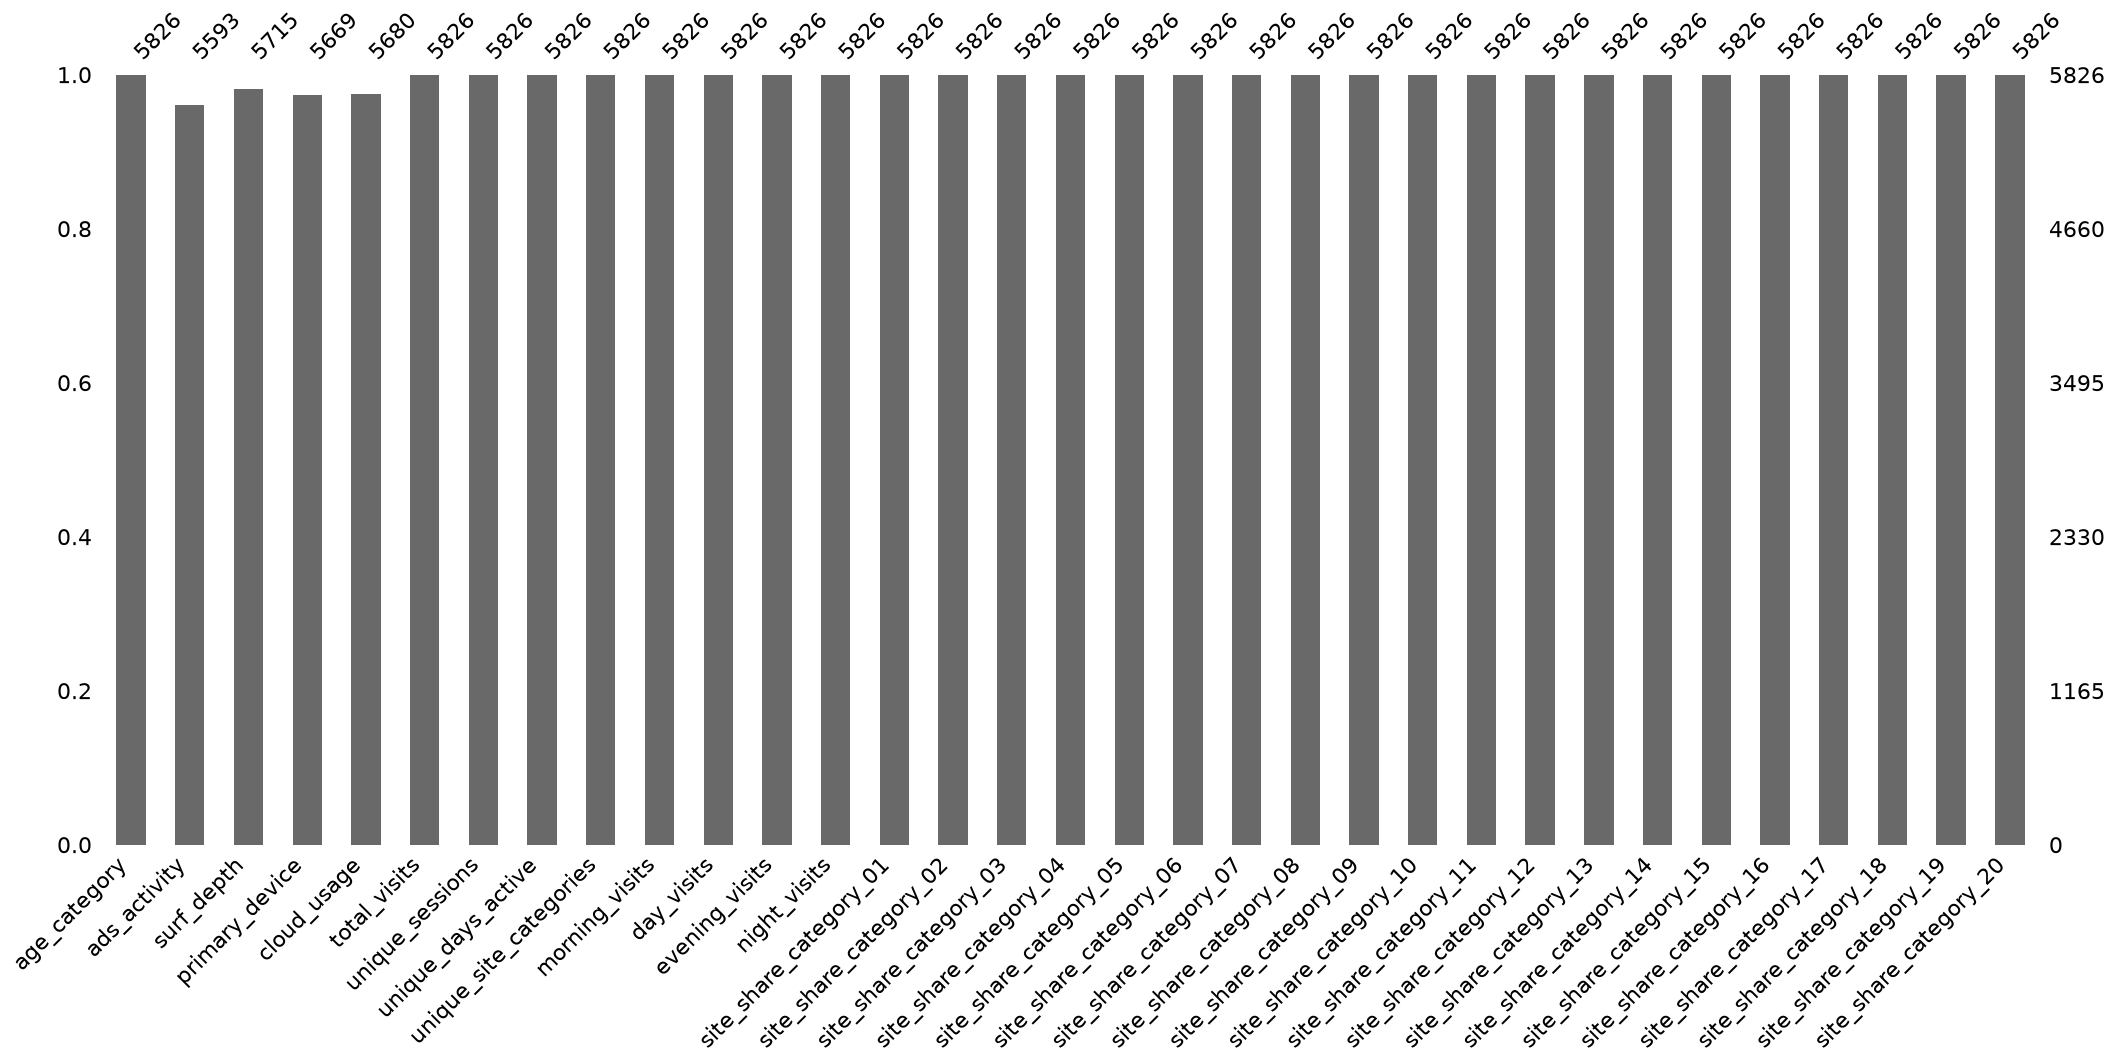

In [32]:
msno.bar(df_clean)

<Axes: >

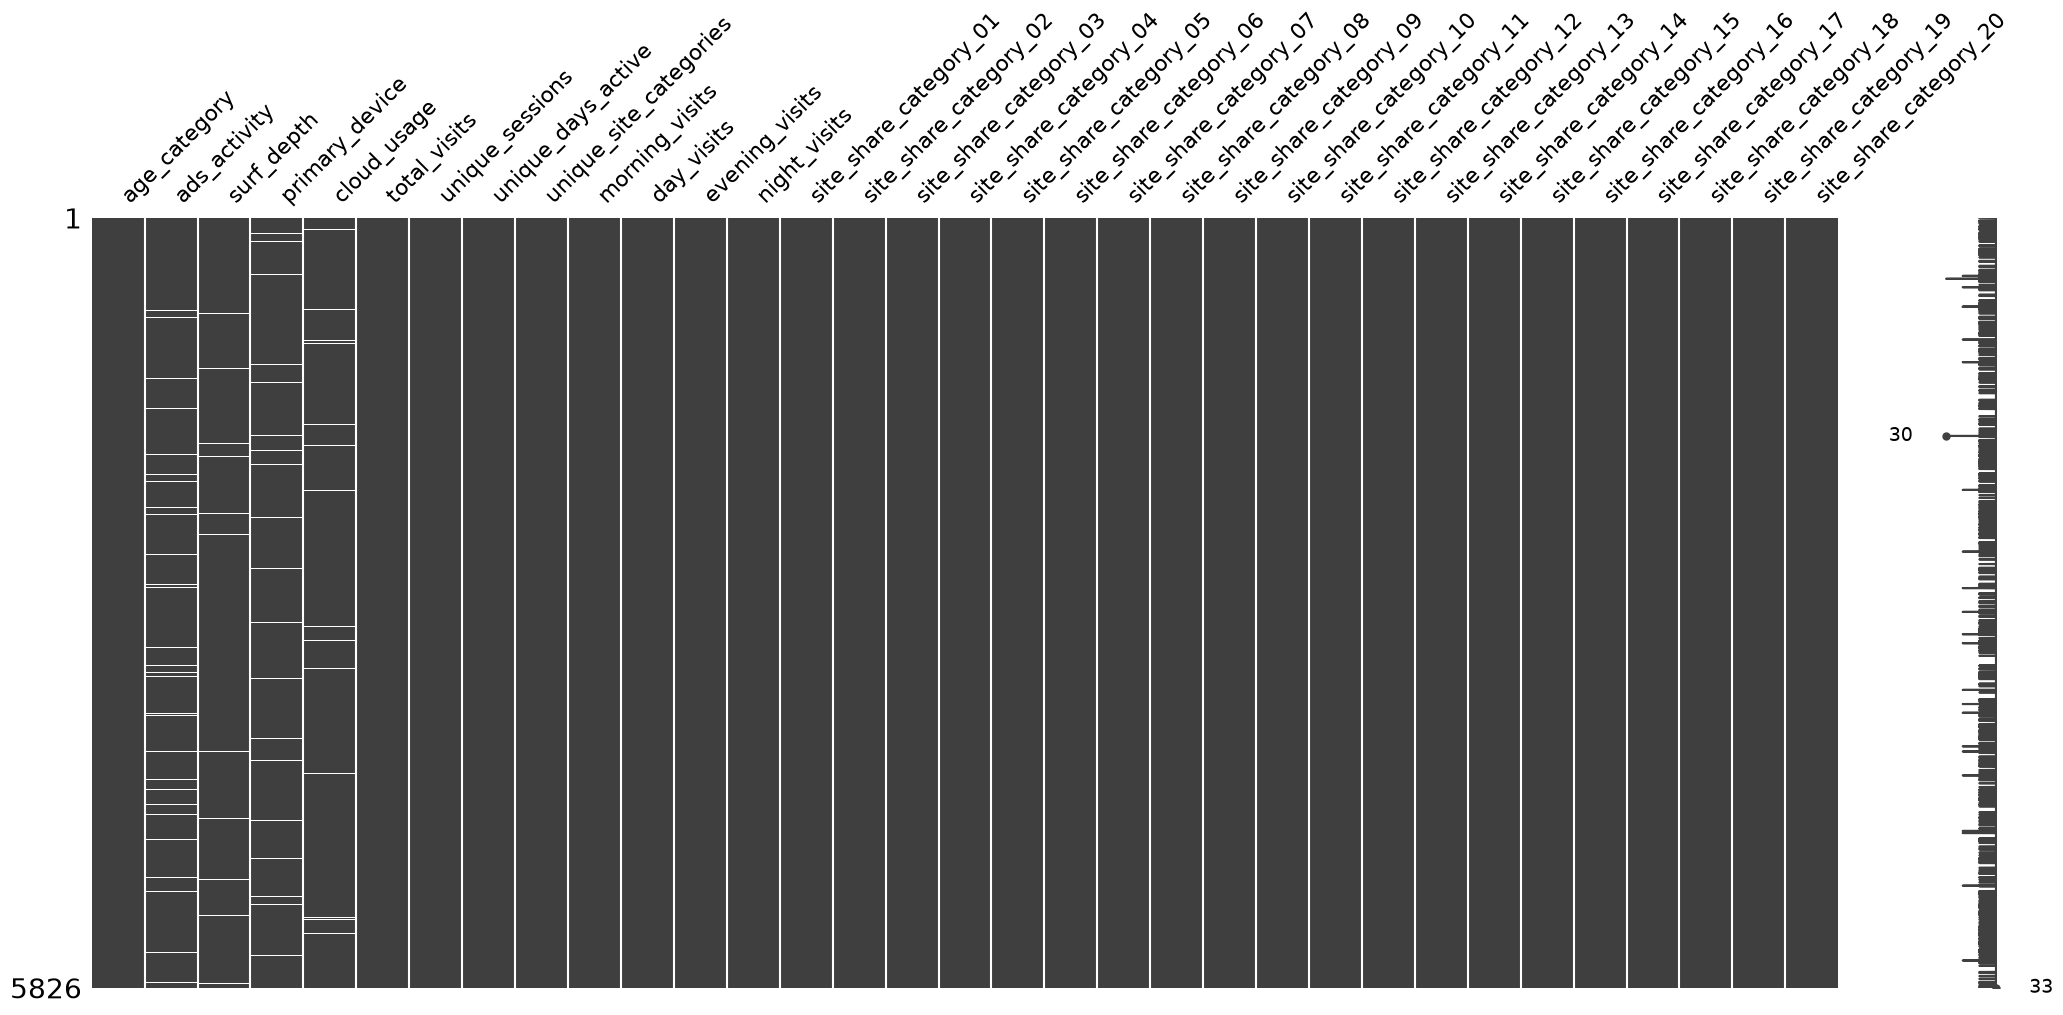

In [33]:
msno.matrix(df_clean)

В датасете распределение пропущенных значений выглядит случайным. Пропуски присутствуют только в столбцах `ads_activity`, `surf_depth`, `primary_device`, `cloud_usage`. Рассмотрим пропуски подробнее.

In [34]:
missing_info = pd.DataFrame({
    'Пропусков': df_clean.isnull().sum(),
    'Всего': len(df_clean),
    'Доля пропусков, %': ((df_clean.isnull().sum() / len(df_clean)) * 100).round(2)
})
missing_info = missing_info[missing_info['Пропусков']>0].sort_values('Пропусков', ascending=False)

missing_info

,Пропусков,Всего,"Доля пропусков, %"
ads_activity,233,5826,4.00
primary_device,157,5826,2.69
cloud_usage,146,5826,2.51
surf_depth,111,5826,1.91


#### Выводы
Пропуски в датасете присутствуют только в 4 признаках - 3 категориальных и 1 бинарном.

- Максимальная доля составляет 4% в `ads_activity`, что является допустимым. Такие пропуски не оказывают критического влияния на качество модели.
- Визуализация показывает, что пропуски распределены по датасету равномерно, без явных паттернов или кластеров. Это указывает на то, что пропуски имеют характер MCAR — то есть их появление не связано ни с целевой переменной, ни с другими признаками.

**Работа с пропусками**
1. Пропуски в категориальных столбцах будут заполняться значением `unknown`, удаление столбцов могло бы привести к утечке данных.
2. Пропуски в юбинарном признаке `cloud_usage` будут заполнены наиболее частым значением.

### Генерация новых признаков
Создадим признаки, хранящие информацию о долях активности по времени суток:

In [35]:
df_clean['ratio_morning'] = (df_clean['morning_visits'] / df_clean['total_visits']).round(3)
df_clean['ratio_day'] = (df_clean['day_visits'] / df_clean['total_visits']).round(3)
df_clean['ratio_evening'] = (df_clean['evening_visits'] / df_clean['total_visits']).round(3)
df_clean['ratio_night'] = (df_clean['night_visits'] / df_clean['total_visits']).round(3)

optimization(df_clean, ['ratio_morning', 'ratio_day', 'ratio_evening', 'ratio_night'], 'Float64')

,age_category,ads_activity,surf_depth,primary_device,cloud_usage,total_visits,unique_sessions,unique_days_active,unique_site_categories,morning_visits,day_visits,evening_visits,night_visits,site_share_category_01,site_share_category_02,site_share_category_03,site_share_category_04,site_share_category_05,site_share_category_06,site_share_category_07,site_share_category_08,site_share_category_09,site_share_category_10,site_share_category_11,site_share_category_12,site_share_category_13,site_share_category_14,site_share_category_15,site_share_category_16,site_share_category_17,site_share_category_18,site_share_category_19,site_share_category_20,ratio_morning,ratio_day,ratio_evening,ratio_night
0,4,NaN,глубоко,смартфон,0,187,187,14,19,43,67,63,14,0.064000003039837,0.037000000476837,0.037000000476837,0.059000000357628,0.101999998092651,0.020999999716878,0.0,0.048000000417233,0.101999998092651,0.027000000700355,0.075000002980232,0.016000000759959,0.032000001519918,0.037000000476837,0.052999999374151,0.043000001460314,0.059000000357628,0.070000000298023,0.075000002980232,0.043000001460314,0.230000004172325,0.358000010251999,0.337000012397766,0.075000002980232
1,2,умеренно,средне,смартфон,0,141,141,14,19,25,48,55,13,0.064000003039837,0.043000001460314,0.098999999463558,0.020999999716878,0.057000000029802,0.035000000149012,0.105999998748302,0.105999998748302,0.043000001460314,0.071000002324581,0.043000001460314,0.043000001460314,0.035000000149012,0.0,0.064000003039837,0.035000000149012,0.035000000149012,0.028000000864267,0.035000000149012,0.035000000149012,0.177000001072884,0.340000003576279,0.389999985694885,0.092000000178814
2,0,умеренно,средне,смартфон,0,100,100,14,17,20,29,38,13,0.009999999776483,0.070000000298023,0.0,0.109999999403954,0.070000000298023,0.129999995231628,0.0,0.03999999910593,0.0,0.009999999776483,0.029999999329448,0.150000005960464,0.119999997317791,0.009999999776483,0.019999999552965,0.029999999329448,0.019999999552965,0.009999999776483,0.109999999403954,0.059999998658895,0.200000002980232,0.28999999165535,0.379999995231628,0.129999995231628
3,4,редко,поверхностно,смартфон,1,248,248,14,19,57,109,64,18,0.081000000238419,0.00400000018999,0.101000003516674,0.028000000864267,0.108999997377396,0.048000000417233,0.028000000864267,0.064999997615814,0.059999998658895,0.0,0.064999997615814,0.016000000759959,0.076999999582767,0.019999999552965,0.024000000208616,0.028000000864267,0.064999997615814,0.133000001311302,0.035999998450279,0.012000000104308,0.230000004172325,0.439999997615814,0.257999986410141,0.072999998927116
4,0,очень редко,поверхностно,смартфон,1,119,119,14,19,19,41,50,9,0.06700000166893,0.041999999433756,0.092000000178814,0.034000001847744,0.050000000745058,0.00800000037998,0.050000000745058,0.06700000166893,0.07599999755621,0.041999999433756,0.041999999433756,0.126000002026558,0.0,0.083999998867512,0.025000000372529,0.025000000372529,0.050000000745058,0.034000001847744,0.025000000372529,0.059000000357628,0.159999996423721,0.344999998807907,0.419999986886978,0.07599999755621
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5821,0,умеренно,средне,планшет,1,213,213,14,19,43,72,75,23,0.089000001549721,0.046999998390675,0.032999999821186,0.061000000685453,0.075000002980232,0.037999998778105,0.023000000044703,0.056000001728535,0.037999998778105,0.075000002980232,0.037999998778105,0.041999999433756,0.0,0.070000000298023,0.028000000864267,0.00899999961257,0.070000000298023,0.075000002980232,0.08500000089407,0.046999998390675,0.202000007033348,0.337999999523163,0.351999998092651,0.108000002801418
5822,3,редко,глубоко,смартфон,0,160,160,14,19,29,63,60,8,0.056000001728535,0.018999999389052,0.061999998986721,0.043999999761581,0.068999998271465,0.093999996781349,0.018999999389052,0.0,0.050000000745058,0.075000002980232,0.025000000372529,0.025000000372529,0.075000002980232,0.030999999493361,0.087999999523163,0.08799999952

Так же создадим признак, который будет хранить активность за сессию:

In [36]:
df_clean['avg_visits_per_session'] = df_clean['total_visits'] / df_clean['unique_sessions']

### Распределение данных и анализ выбросов

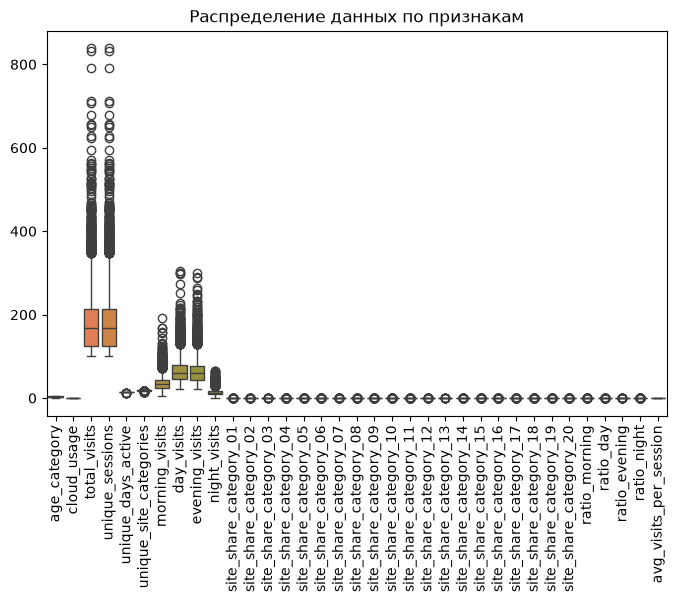

In [37]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df_clean, vert=True)
plt.xticks(rotation=90)
plt.title("Распределение данных по признакам")
plt.show()

Признаки `total_visits` и `unique_sessions` имеют довольно крупный разброс. Так же выбросы присутствуют во временных признаках. Рассмотрим их:

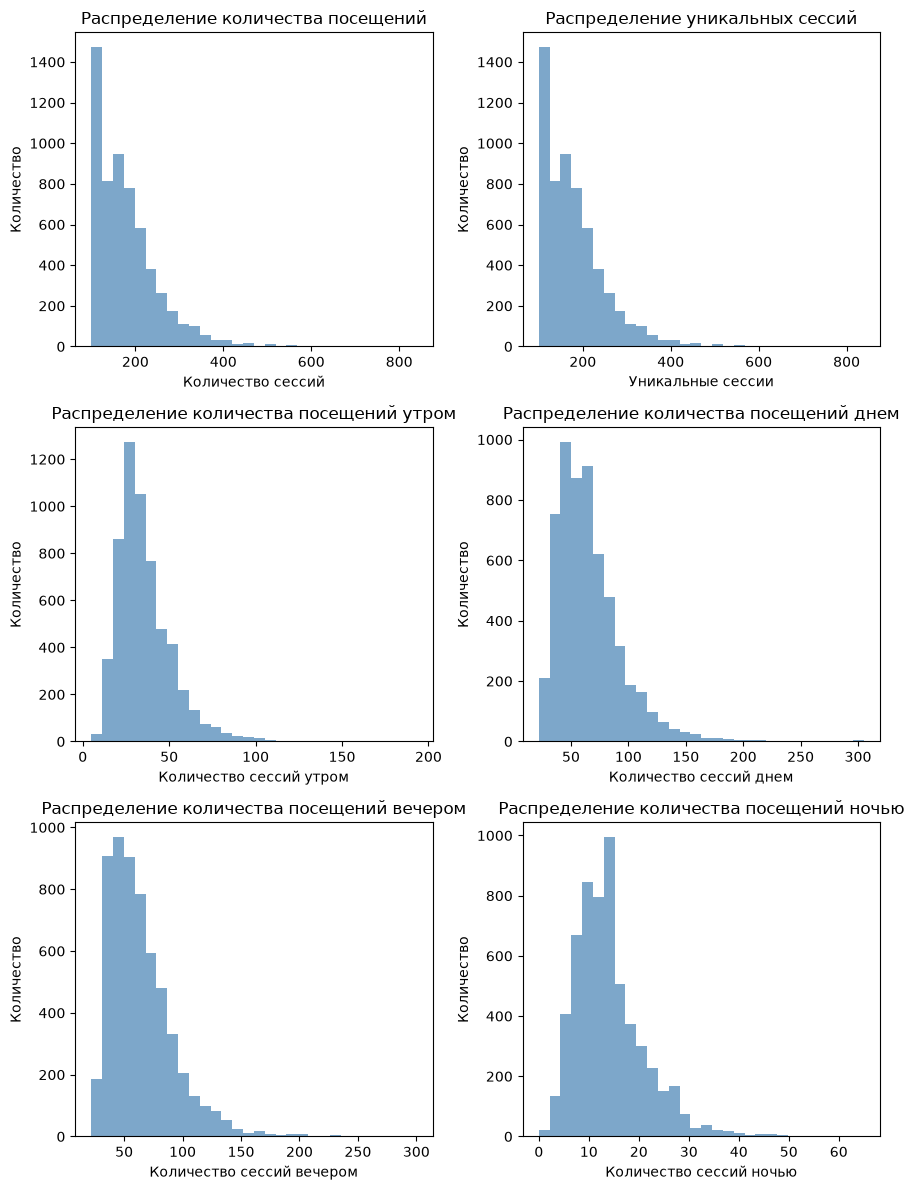

In [38]:
fig, axes =  plt.subplots(3,2, figsize=(9,12))
axes[0][0].hist(df_clean['total_visits'], bins=30, color='steelblue', alpha=0.7)
axes[0][0].set_title('Распределение количества посещений')
axes[0][0].set_ylabel('Количество')
axes[0][0].set_xlabel('Количество сессий')

axes[0][1].hist(df_clean['unique_sessions'], bins=30, color='steelblue', alpha=0.7)
axes[0][1].set_title('Распределение уникальных сессий')
axes[0][1].set_ylabel('Количество')
axes[0][1].set_xlabel('Уникальные сессии')

axes[1][0].hist(df_clean['morning_visits'], bins=30, color='steelblue', alpha=0.7)
axes[1][0].set_title('Распределение количества посещений утром')
axes[1][0].set_ylabel('Количество')
axes[1][0].set_xlabel('Количество сессий утром')
axes[1][1].hist(df_clean['day_visits'], bins=30, color='steelblue', alpha=0.7)
axes[1][1].set_title('Распределение количества посещений днем')
axes[1][1].set_ylabel('Количество')
axes[1][1].set_xlabel('Количество сессий днем')

axes[2][0].hist(df_clean['evening_visits'], bins=30, color='steelblue', alpha=0.7)
axes[2][0].set_title('Распределение количества посещений вечером')
axes[2][0].set_ylabel('Количество')
axes[2][0].set_xlabel('Количество сессий вечером')

axes[2][1].hist(df_clean['night_visits'], bins=30, color='steelblue', alpha=0.7)
axes[2][1].set_title('Распределение количества посещений ночью')
axes[2][1].set_ylabel('Количество')
axes[2][1].set_xlabel('Количество сессий ночью')

plt.tight_layout()
plt.show()

**По распределениям видно:**

На всех графиках присутствует  правосторонняя ассиметрия.
1. Графики `total_visits` и `unique_sessions` почти совпадают, что указывает на сильную корреляцию, необходимо будет проверить данные на мультиколлинеарность.
   Большинство пользователей имеют 100-200 сессий, небольшая доля пользователей имеет 500-800.

   Пользователи с 600-850 визитами — это аномально активные пользователи. Они могут быть ботами, тестировщиками или очень лояльными пользователями.
3. Графики временных признаков имеют более близкое к нормальному распределение, но все равно имеют скошенность вправо.
  


Признаки могут нести важную информацию, поэтому будем использовать **логарифмическое преобразование**:

In [39]:
count_features = ['total_visits', 'unique_sessions', 
                  'morning_visits', 'day_visits', 'evening_visits', 'night_visits']
for feat in count_features:
    if feat in df_clean.columns:
        df_clean[f'{feat}_log'] = np.log1p(df_clean[feat]) 

df_clean = df_clean.drop(columns=count_features)

Так же логарифмом усилим разброс признаков, отвечающих за категории сайтов:

In [40]:
site_share_cols = [col for col in df_clean.columns if 'site_share_category' in col]
time_cols = [col for col in df_clean.columns if 'ratio' in col]
for col in (site_share_cols+time_cols):
    df_clean[f'{col}_log'] = np.log1p(df_clean[col] * 100) 

df_clean = df_clean.drop(columns=(site_share_cols+time_cols))

**Посмотрим текущее распределение признаков:**

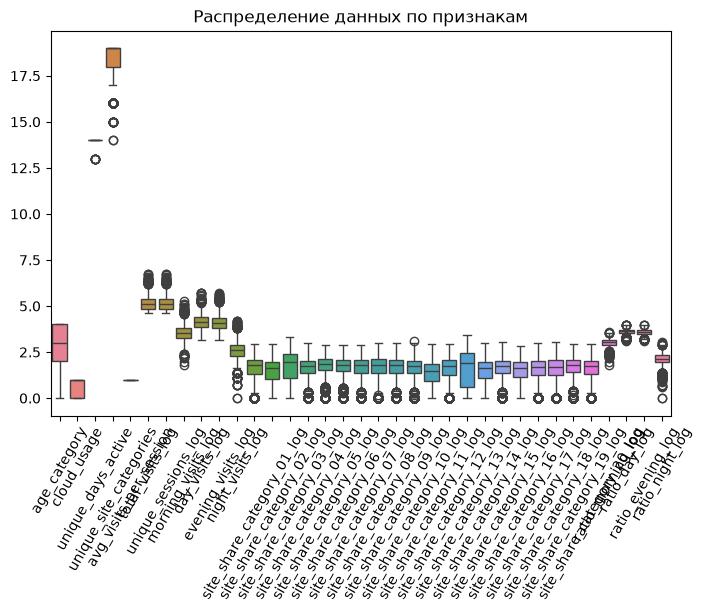

In [41]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df_clean, vert=True)
plt.xticks(rotation=60)
plt.title("Распределение данных по признакам")
plt.show()

Теперь распределение выглядит более равномерно. Рассмотрим подробнее исправленные признаки, которые сильно выделялись:

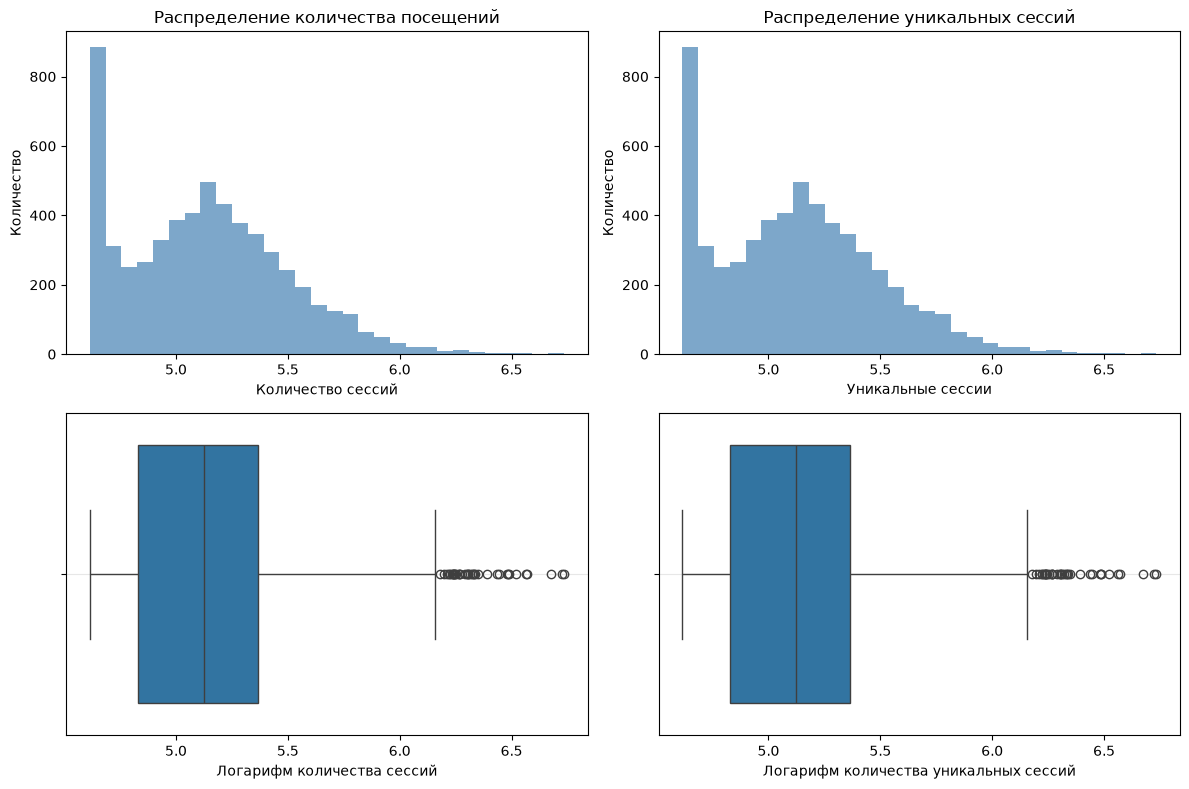

In [42]:
fig, axes =  plt.subplots(2,2, figsize=(12,8))
axes[0][0].hist(df_clean['total_visits_log'], bins=30, color='steelblue', alpha=0.7)
axes[0][0].set_title('Распределение количества посещений')
axes[0][0].set_ylabel('Количество')
axes[0][0].set_xlabel('Количество сессий')

axes[0][1].hist(df_clean['unique_sessions_log'], bins=30, color='steelblue', alpha=0.7)
axes[0][1].set_title('Распределение уникальных сессий')
axes[0][1].set_ylabel('Количество')
axes[0][1].set_xlabel('Уникальные сессии')

sns.boxplot(x=df_clean['total_visits_log'], ax=axes[1][0],vert=False)
axes[1][0].set_xlabel("Логарифм количества сессий")
axes[1][0].grid(alpha=0.3, axis='y')

sns.boxplot(x=df_clean['unique_sessions_log'], ax=axes[1][1],vert=False)
axes[1][1].set_xlabel("Логарифм количества уникальных сессий")
axes[1][1].grid(alpha=0.3, axis='y')
        

plt.tight_layout()
plt.show()

После сглаживания логарифмированием распределение стало более гладким, правостороннее смещение сохранилось, но теперь оно уже ближе к нормальному. 

Созданный признак почти не варьируется, большинство пользователей совершают 1-2 посещения за сессию. Удалим его.
Так же признак `unique_days_active` и `unique_site_categories` является константным, он тоже требует удаления.


In [43]:
df_clean = df_clean.drop(columns=['avg_visits_per_session', 'unique_days_active', 'unique_site_categories'])

#### Выводы
В ходе анализа было выявлено несколько признаков с выраженными выбросами:

| Признак | Характер выбросов | Максимальное значение |
|---|---|---|
| `total_visits` | Сильная правосторонняя асимметрия | ~850 посещений |
| `unique_sessions` | Сильная правосторонняя асимметрия | ~850 сессий |
| `morning_visits` | Правосторонняя ассиметрия | Выбросы до 200 |
| `day_visits` | Правосторонняя ассиметрия | Выбросы до 300 |
| `evening_visits` | Правосторонняя ассиметрия | Выбросы до 300 |
| `night_visits` | Правосторонняя ассиметрия | Выбросы до 100 |

**Ключевые наблюдения:**

1. Выбросы в `total_visits` и `unique_sessions` связаны с наличием супер-активных пользователей. Распределения имеют сильную правостороннюю асимметрию — основная масса пользователей сосредоточена в диапазоне 100–250 визитов, но есть "длинный хвост" из пользователей с 600–850+ визитами.

2. Высокая корреляция между `total_visits` и `unique_sessions` указывает на то, что пользователи совершают 1 посещение за сессию. Признаки будут вызывать мультиколлинеарность друг с другом. Рассмотрим на этапе корреляций.

3. Выбросы в категориях, связанных с активностью в определенное время суток связаны с тем, что в любой возрастной категории будут люди, отличающиеся поведением от таких же людей своего возраста.

5. Попытка создать производный признак `visits_per_session = total_visits / unique_sessions` не увенчалась успехом — большинство пользователей имеют значение в узком диапазоне 1.00–1.02, что делает признак практически константным и бесполезным для модели.

Применено **логарифмическое преобразование** для признаков `total_visits` и `unique_sessions`. Так же оно применено для увеличения разброса признаков по категориям сайтов. Для масштабирования признаков будем использовать `RobustScaler`. 

### Промежуточный вывод о проделанной работе:

1. **Общая характеристика датасета**
    | Исходный датафрейм | Текущий |
    | --- | --- |
    | 6146 строка | 5826 строк |
    | 34 столбцов | 35 столбцов |

2. **Целевая переменная**
    - Выявлен **умеренный дисбаланс классов**: соотношение наибольшего класса (категория 4, 30.3%) к наименьшему (категория 1, 8.8%) составляет 3.4
    - Распределение имеет тенденцию: чем старше возрастная категория, тем больше пользователей
    - **Стратегия:** использовать `class_weight='balanced'` при обучении и метрику `F1-weighted` для оценки

2. **Обработка пропусков**

    Пропуски обнаружены только в 4 категориальных признаках категориальные признаки (`ads_activity`, `surf_depth`, `primary_device`) будут заполняться значением `unknown`, бинарный признак `cloud_usage` - наиболее частым значением.
  
3. **Анализ выбросов**
    
    **Выявленные проблемы:**
    - Признаки `total_visits` и `unique_sessions` имеют сильную правостороннюю асимметрию (выбросы до 850+ значений)
    - Высокая корреляция между `total_visits` и `unique_sessions` 
    
      Применено логарифмическое преобразование `log1p()` для `total_visits` и `unique_sessions` — успешно сжало правый хвост распределения, а так же для признаков с категориями сайтов - это помогло увеличить разброс для лучшего восприятия моделью.   

6. **Информативность признаков**

    **Высокая важность:**
    - Признаки с категориями сайтов
    - `cloud_usage`
      
    **Умеренная важность:**
    - Признаки с распределением посещений по времени суток (кроме `day_visits`)
    - `ads_activity` — слабая дифференциация возрастных групп
    - `surf_depth` — пользователи с глубоким погружением немного моложе
    - `site_share_category_05`

    **Низкая важность:**
    Остальные признаки


   Решение об удалении признаков на основе корреляций будет применяться на этапе отбора признаков.

## Предобработка данных
### Разделение данных на выборки
Разделим данные в пропорции 60/15/20/20. 20% на тестовую выборку.

In [44]:
X = df_clean.drop(columns=['age_category'])
y = df_clean['age_category']

X_temp1, X_test, y_temp1, y_test = train_test_split(X, y, random_state=42, test_size=0.2, stratify=y)
X_temp2, X_calibrated, y_temp2, y_calibrated = train_test_split(X_temp1, y_temp1, random_state=42, test_size=0.25, stratify=y_temp1)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp2, y_temp2, test_size=0.25, random_state=42, stratify=y_temp2
)


print(f"Train: {len(X_train)} строк, {len(X_train)/len(X)*100:.2f}%")
print(f"Validation: {len(X_val)} строк, {len(y_val)/len(X)*100:.2f}%")
print(f"Calibrated: {len(X_calibrated)} строк, {len(y_calibrated)/len(X)*100:.2f}%")
print(f"Test: {len(X_test)} строк, {len(X_test)/len(X)*100:.2f}%\n")

Train: 2621 строк, 44.99%
Validation: 874 строк, 15.00%
Calibrated: 1165 строк, 20.00%
Test: 1166 строк, 20.01%



Посмотрим распределение в выборках:

In [45]:
print("Распределение целевой переменной (age_category) в выборках:\n")

for split_name, y_split in [("Train", y_train), ("Validation", y_val), ("Calibrated", y_calibrated), ("Test", y_test)]:
    print(f"{split_name} ({len(y_split)} строк)")
    
    counts = y_split.value_counts().sort_index()
    total = len(y_split)
    
    for category, count in counts.items():
        pct = (count / total) * 100
        print(f"  Категория {category}: {count:>4} строк ({pct:.1f}%)")

Распределение целевой переменной (age_category) в выборках:

Train (2621 строк)
  Категория 0:  384 строк (14.7%)
  Категория 1:  231 строк (8.8%)
  Категория 2:  647 строк (24.7%)
  Категория 3:  564 строк (21.5%)
  Категория 4:  795 строк (30.3%)
Validation (874 строк)
  Категория 0:  128 строк (14.6%)
  Категория 1:   77 строк (8.8%)
  Категория 2:  216 строк (24.7%)
  Категория 3:  188 строк (21.5%)
  Категория 4:  265 строк (30.3%)
Calibrated (1165 строк)
  Категория 0:  170 строк (14.6%)
  Категория 1:  103 строк (8.8%)
  Категория 2:  288 строк (24.7%)
  Категория 3:  251 строк (21.5%)
  Категория 4:  353 строк (30.3%)
Test (1166 строк)
  Категория 0:  171 строк (14.7%)
  Категория 1:  103 строк (8.8%)
  Категория 2:  288 строк (24.7%)
  Категория 3:  251 строк (21.5%)
  Категория 4:  353 строк (30.3%)


### Создание паплайнов

In [46]:
num_tranfromer = Pipeline(steps=[ 
    # пропуски отсутствуют, но это будет подстраховкой для других данных
    ('imputer', SimpleImputer(strategy='median')), 
    ('scaler', RobustScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='first')),
])

bin_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent', fill_value=0))
])

**Объединение паплайнов через `ColumnTransformer`**

In [47]:
preprocessor = ColumnTransformer(transformers=[
    ('num', num_tranfromer, make_column_selector(dtype_include=np.number)),
    ('cat', cat_transformer, make_column_selector(dtype_include='category')),
    ('bin', bin_transformer, make_column_selector(dtype_include='Int8'))
], remainder='drop'
)                                 

### Проверка паплайна на данных

In [48]:
X_train_processed = preprocessor.fit_transform(X_train, y_train)

print(f"X_train_processed: {X_train_processed.shape}")

X_train_processed: (2621, 41)


In [49]:
train_missing = np.isnan(X_train_processed).sum()

print(f"Пропусков в X_train_processed: {train_missing}")

Пропусков в X_train_processed: 0


### Промежуточные выводы
1. Проведено **разделение данных** в пропорции 60/15/20/20 со стратификацией - дисбаланс 14.6% сохранён во всех выборках.
2. Создан единый **ColumnTransformer**, который для разных типов признаков применяет свои стратегии:
    - Числовые: заполнение медианой + масштабирование.
    - Категориальные: заполнение наиболее частым и One-Hot Encoding (с удалением первой категории для избежания мультиколлинеарности).
    - Бинарные: заполнение наиболее частым значением.

## Отбор признаков

### Анализ категориальных признаков

In [50]:
df_train = X_train.copy()
df_train['age_category'] = y_train

category_cols = df_train.select_dtypes(include=['category']).columns.tolist()
print(f'Количество категориальных признаков: {len(category_cols)}')

for col in category_cols:
    n_unique = df_train[col].nunique()
    n_missing = df_train[col].isnull().sum()
    pct_missing = n_missing / len(df_train) * 100
    print(f"{col:<25} уникальных: {n_unique}, пропусков: {n_missing}, % пропусков: {pct_missing:.2f}%")

Количество категориальных признаков: 3
ads_activity              уникальных: 5, пропусков: 120, % пропусков: 4.58%
surf_depth                уникальных: 3, пропусков: 58, % пропусков: 2.21%
primary_device            уникальных: 4, пропусков: 63, % пропусков: 2.40%


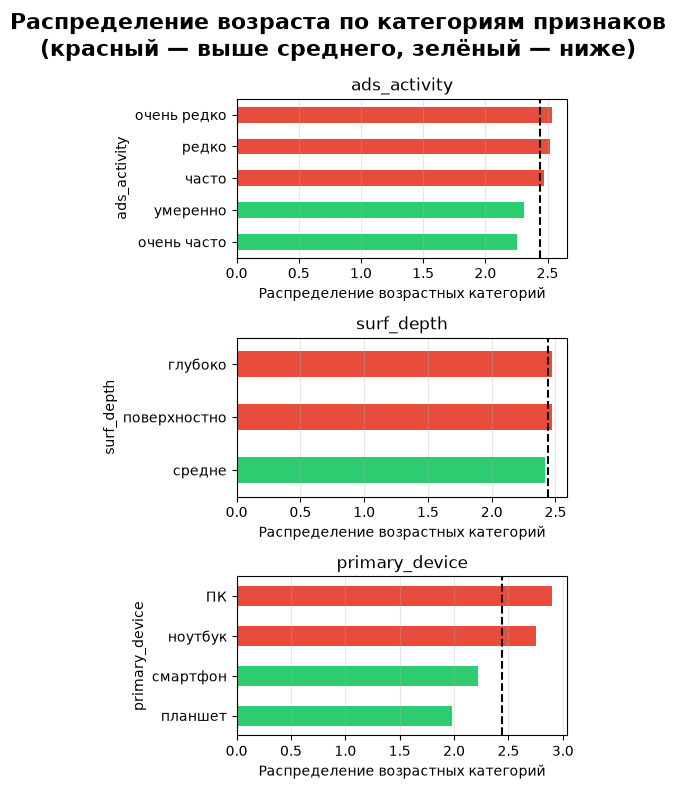

In [51]:
fig, axes = plt.subplots(3, 1, figsize=(5, 8))

base_churn = df_train['age_category'].mean()

for ax, col in zip(axes, category_cols):
    churn_by_cat = (
        df_train.groupby(col, observed=True)['age_category']
          .mean()  
          .sort_values()
    )

    colors = ['#2ecc71' if x <= base_churn else '#e74c3c' for x in churn_by_cat]

    churn_by_cat.plot(kind='barh', ax=ax, color=colors)

    ax.set_title(col)
    ax.set_xlabel('Распределение возрастных категорий')
    ax.axvline(base_churn, color='black', linestyle='--', linewidth=1.5)
    ax.grid(axis='x', alpha=0.3)

plt.suptitle(
    'Распределение возраста по категориям признаков\n(красный — выше среднего, зелёный — ниже)',
    fontsize=16, fontweight='bold'
)
plt.tight_layout()
plt.show()

#### Выводы
- `primary_device` - наиболее информативный признак.
    Предпочтения устройств сильно коррелируют с возрастом. Пользователи ПК и ноутбуков — преимущественно старшие возрастные группы, тогда как пользователи смартфонов и планшетов — более молодые.

- Признак `surf_depth` не сильно влияет на возраст, пользователи которые просматривают сайты глубоко, немного моложе, но разница не очень значительная.

- Признак `ads_activity` имеет минимальные различия между категориями, он слабо дифференцирует возрастные группы.

Для всех признаков будет применяться кодирование `One-Hot-Encoding`, т.к. все признаки имеют небольшое количество категорий. Полезность признаков более тщательно будет рассмотрена на этапе корреляций.

### Корреляционный анализ между признаками и целевой переменной

In [52]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 2621 entries, 2591 to 5046
Data columns (total 34 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   ads_activity                2501 non-null   category
 1   surf_depth                  2563 non-null   category
 2   primary_device              2558 non-null   category
 3   cloud_usage                 2573 non-null   Int8    
 4   total_visits_log            2621 non-null   Float32 
 5   unique_sessions_log         2621 non-null   Float32 
 6   morning_visits_log          2621 non-null   Float32 
 7   day_visits_log              2621 non-null   Float32 
 8   evening_visits_log          2621 non-null   Float32 
 9   night_visits_log            2621 non-null   Float32 
 10  site_share_category_01_log  2621 non-null   Float32 
 11  site_share_category_02_log  2621 non-null   Float32 
 12  site_share_category_03_log  2621 non-null   Float32 
 13  site_share_category_04_log  262

Для начала визуализируем тепловую карту **корреляции между всеми признаками**: 

Числовые: ['cloud_usage', 'total_visits_log', 'unique_sessions_log', 'morning_visits_log', 'day_visits_log', 'evening_visits_log', 'night_visits_log', 'site_share_category_01_log', 'site_share_category_02_log', 'site_share_category_03_log', 'site_share_category_04_log', 'site_share_category_05_log', 'site_share_category_06_log', 'site_share_category_07_log', 'site_share_category_08_log', 'site_share_category_09_log', 'site_share_category_10_log', 'site_share_category_11_log', 'site_share_category_12_log', 'site_share_category_13_log', 'site_share_category_14_log', 'site_share_category_15_log', 'site_share_category_16_log', 'site_share_category_17_log', 'site_share_category_18_log', 'site_share_category_19_log', 'site_share_category_20_log', 'ratio_morning_log', 'ratio_day_log', 'ratio_evening_log', 'ratio_night_log', 'age_category']
Категориальные: ['ads_activity', 'surf_depth', 'primary_device']


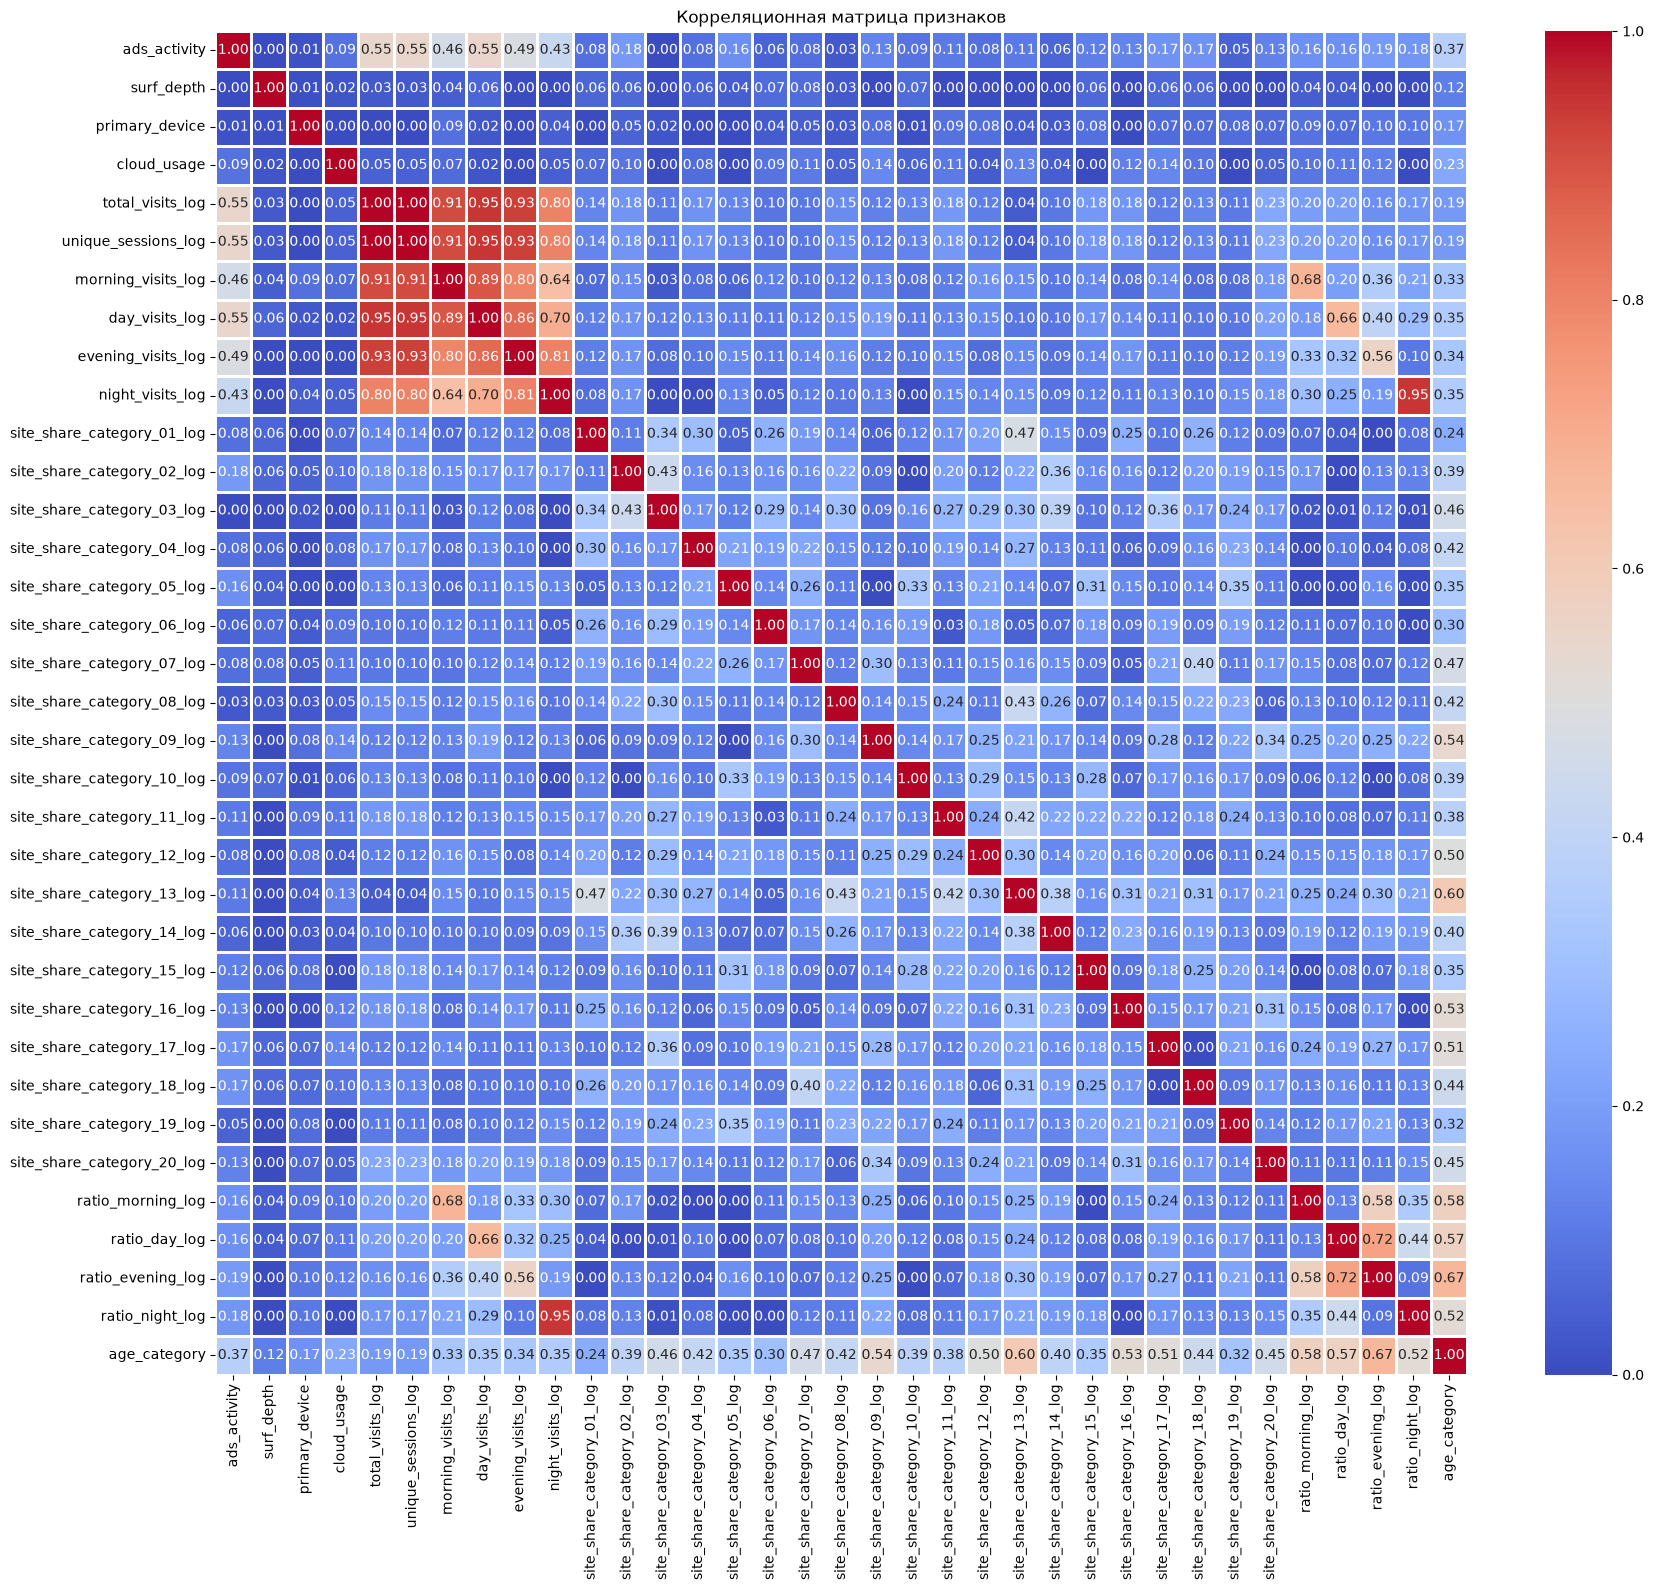

In [53]:
df_for_phik = X_train.copy()
df_for_phik['age_category'] = y_train

num_cols = df_for_phik.select_dtypes(include=['number']).columns.tolist()
cat_cols = df_for_phik.select_dtypes(include=['category']).columns.tolist()

print('Числовые:', num_cols)
print('Категориальные:', cat_cols)

phik_result = phik_matrix(df_for_phik, interval_cols=num_cols)

plt.figure(figsize=(18, 16))
sns.heatmap(phik_result, annot=True, fmt='.2f', cmap='coolwarm', linewidths=1)
plt.title('Корреляционная матрица признаков')
plt.tight_layout()
plt.show()

- В данных присутствует крупная мультиколлинеарность. Признаки `unique_session_log` и `total_visits_log` действительно очень сильно коррелируют, коэффициент корреляции - 1. Один из признаков требует удаления.

- Так же присутствует сильная мультиколлинеарность (>0.9) у признаков, которые содержат количественную информацию о посещениях в определенное время суток (не доли), нужно удалить их.

- Мультиколлинеарность между признаками `ads_activity` с `total_visits_log` и `unique_session_log`, и временными признаками - ~0.5.

Так же в данных присутствует мультиколлинеарность еще между многими признаками, но она менее выделяющаяся

**Построим столбчатые диаграммы для визуализации связи признаков с целевой переменной:**

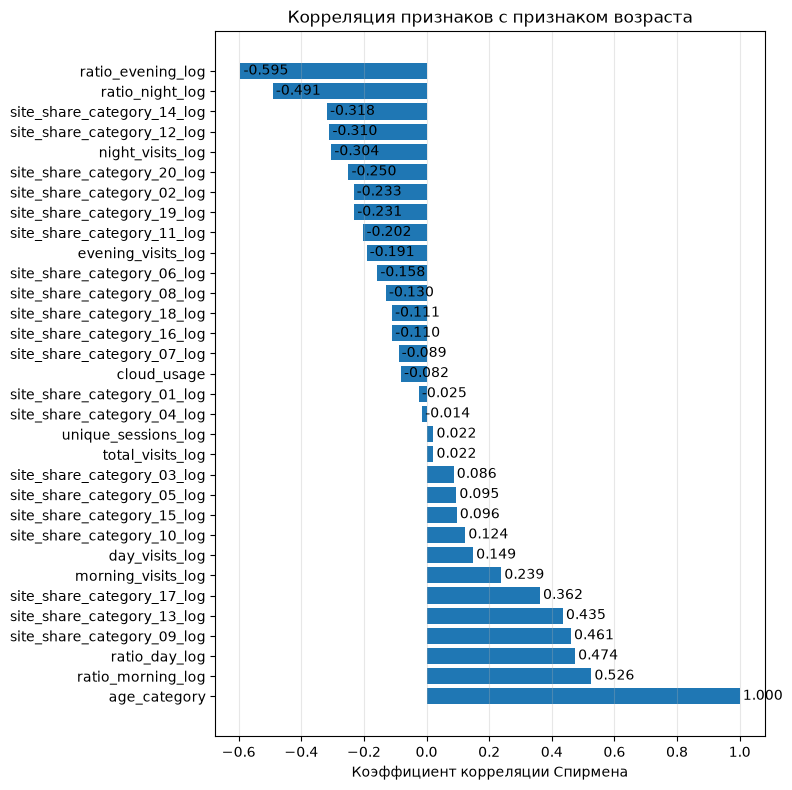

,Корреляция Спирмена с признаком возраста
ratio_morning_log,0.526195418599463
ratio_day_log,0.474147326346585
site_share_category_09_log,0.460954540200053
site_share_category_13_log,0.435238000685741
site_share_category_17_log,0.362062158593755
morning_visits_log,0.238527716708384
day_visits_log,0.148514657832686
site_share_category_10_log,0.123586003095289
site_share_category_15_log,0.096305553333606
site_share_category_05_log,0.094881592156120


In [54]:
target_col = 'age_category' 
corr_df = X_train.select_dtypes(include='number')
corr_df[target_col] = y_train
correlation = corr_df.corr(method='spearman')[target_col].sort_values(ascending=False)

plt.figure(figsize=(8,8))
plt.barh(correlation.index, correlation.values)
plt.xlabel('Коэффициент корреляции Спирмена')
plt.title('Корреляция признаков с признаком возраста')
plt.grid(axis='x', alpha=0.3)

for i, (feat, corr) in enumerate(correlation.items()):
    plt.text(corr + 0.01, i+0.01, f'{corr:.3f}', va='center', fontsize=10)
  
plt.tight_layout()
plt.show()

corr_frame = (
    correlation
    .to_frame(name='Корреляция Спирмена с признаком возраста')
    .drop('age_category')
)
corr_frame

#### Выводы 
1. **Мультиколлинеарность между признаками**
   - Идеальная корреляция между `total_visits_log` и `unique_session_log`: *r = 1.00*. Признаки практически идентичны, так как пользователи совершают 1 посещение за сессию. Признак `unique_sessions_log` бесполезен.
   - Умеренная корреляция между `ads_activity` с признаками `total_visits_log` и `unique_sessions_log`: *r = 0.55*. Это логично: более активные пользователи чаще видят рекламу.
     
2. **Корреляция признаков с целевой переменной**
    Все признаки имеют очень слабую корреляцию с `age_category` или она полностью отсутствует. При таких слабых корреляциях практически невозможно построить точную модель для предсказания возраста.

   Самые перспективные признаки - времени, категории сайтов.

In [55]:
X_train = X_train.drop(columns=['unique_sessions_log', 'morning_visits_log', 'day_visits_log', 'evening_visits_log', 'night_visits_log'])

In [56]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 2621 entries, 2591 to 5046
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   ads_activity                2501 non-null   category
 1   surf_depth                  2563 non-null   category
 2   primary_device              2558 non-null   category
 3   cloud_usage                 2573 non-null   Int8    
 4   total_visits_log            2621 non-null   Float32 
 5   site_share_category_01_log  2621 non-null   Float32 
 6   site_share_category_02_log  2621 non-null   Float32 
 7   site_share_category_03_log  2621 non-null   Float32 
 8   site_share_category_04_log  2621 non-null   Float32 
 9   site_share_category_05_log  2621 non-null   Float32 
 10  site_share_category_06_log  2621 non-null   Float32 
 11  site_share_category_07_log  2621 non-null   Float32 
 12  site_share_category_08_log  2621 non-null   Float32 
 13  site_share_category_09_log  262

### Создание паплайна с фильтрационными методами и методами-обертками

In [57]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('variance', VarianceThreshold(threshold=0.001)),
    ('mi', SelectKBest(score_func=mutual_info_classif, k=30)),
    ('rfecv', RFECV(
                estimator=LogisticRegression(
                    max_iter=1000,
                    random_state=42,
                    class_weight='balanced'
                ),
                step=1,
                cv=StratifiedKFold(
                    n_splits=5,
                    shuffle=True,
                    random_state=42
                ),
                scoring='f1_macro',
                min_features_to_select=1,
                n_jobs=-1
            )),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42,
        class_weight='balanced'
    ))
])

### Проверка применения паплайна

In [58]:
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
cv_results = cross_validate(
    pipeline,
    X_train,
    y_train,
    cv=outer_cv,
    scoring='f1_macro',
    return_train_score=False,
    return_estimator=True,
    n_jobs=-1,
    error_score='raise'
)

pipeline.fit(X_train, y_train)
print(
    'Количество признаков после RFECV:',
    pipeline.named_steps['rfecv'].n_features_
)

Количество признаков после RFECV: 29


### Промежуточные выводы
1. **Корреляционный анализ**

   В данных присутствует большое количество мультиколлинеарности между признаками:
    - Идеальная корреляция между `total_visits_log` и `unique_sessions_log` (r = 1.00)
    - Корреляция >0.8 количественных признаков времени суток с `total_visits_log`, `unique_sessions_log`, а так же их взаимная корреляция между собой. Для избежания этого созданы признаки `ratio_время суток`.
В ходе работы был использован комбинированный подход, сочетающий фильтрационные и wrapper-методы:

2. **Создан паплайн с отбором признаков**, чтобы избежать утечки данных при кросс-валидации. Удаляются признаки с низкой дисперсией с помощью `VarianceThreshold`. После этого с помощью `SelectKBest` и метода `mutual_info_classif` остаётся 30 наиболее информативных признаков. Вместо обычного `RFE`, где количество признаков нужно задавать вручную, использован `RFECV`. Он автоматически подбирает оптимальное количество признаков с помощью внутренней кросс-валидации. Утчеки данных отсутствуют, потому что на каждом фолде заново обучаются предобработка, отбор признаков и логистическая регрессия.

## Обучение модели
### Построение дамми модели
Для построения модели будем использовать стратегию `prior`.

In [59]:
full_dummy_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('variance', VarianceThreshold(threshold=0.001)),
    ('mi', SelectKBest(score_func=mutual_info_classif, k=30)),
    ('rfecv', RFECV(
                estimator=LogisticRegression(
                    max_iter=1000,
                    random_state=42,
                    class_weight='balanced'
                ),
                step=1,
                cv=StratifiedKFold(
                    n_splits=5,
                    shuffle=True,
                    random_state=42
                ),
                scoring='f1_macro',
                min_features_to_select=1,
                n_jobs=-1
            )),
    ('model', DummyClassifier(strategy='prior', random_state=42))
])

### Построение базовой модели логистической регресиии

Учитывая дисбалансы классов, используем `class_weight='balanced'`. Параметр `multi_class` был удален и применяется автоматически, поэтому писать его не нужно.

In [60]:
full_base_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('variance', VarianceThreshold(threshold=0.001)),
    ('mi', SelectKBest(score_func=mutual_info_classif, k=30)),
    ('rfecv', RFECV(
                estimator=LogisticRegression(
                    max_iter=1000,
                    random_state=42,
                    class_weight='balanced'
                ),
                step=1,
                cv=StratifiedKFold(
                    n_splits=5,
                    shuffle=True,
                    random_state=42
                ),
                scoring='f1_macro',
                min_features_to_select=1,
                n_jobs=-1
            )),
    ('model', LogisticRegression(random_state=42, 
                                max_iter=1000, 
                                class_weight='balanced', 
                                solver='lbfgs'))
])


### Построение базовой модели классификации методом опорных векторов
`SVC` тоже автоматически использует мультиклассовую классификацию `One-vs-One`, она больше подходит к нешей задаче, поэтому оставим как есть.

In [61]:
full_base_svc_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('variance', VarianceThreshold(threshold=0.001)),
    ('mi', SelectKBest(score_func=mutual_info_classif, k=30)),
    ('rfecv', RFECV(
                estimator=LogisticRegression(
                    max_iter=1000,
                    random_state=42,
                    class_weight='balanced'
                ),
                step=1,
                cv=StratifiedKFold(
                    n_splits=5,
                    shuffle=True,
                    random_state=42
                ),
                scoring='f1_macro',
                min_features_to_select=1,
                n_jobs=-1
            )),
    ('model', SVC(
        kernel='rbf', random_state=42, class_weight='balanced'
    ))
])

### Кросс-валидация на обучающей выборке

In [62]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'f1_macro': make_scorer(f1_score, average='macro'),
    'f1_weighted': make_scorer(f1_score, average='weighted'),
    'precision_macro': make_scorer(precision_score, average='macro'),
    'precision_weighted': make_scorer(precision_score, average='weighted'),
    'recall_macro': make_scorer(recall_score, average='macro'),
    'recall_weighted': make_scorer(recall_score, average='weighted')
}
# Кросс-валидация модели логистической регрессии:
cv_results = cross_validate(full_base_pipeline, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False)

# Кросс-валидация дамми модели:
dummy_cv_results = cross_validate(full_dummy_pipeline, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False)

# Кросс-валидация SVC модели:
svc_cv_results = cross_validate(full_base_svc_pipeline, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False)

In [63]:
full_base_pipeline.fit(X_train, y_train)
full_dummy_pipeline.fit(X_train, y_train)
full_base_svc_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('variance', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](5,)","[0.,1.,2.,3.,4.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](29,)","['ads_activity','surf_depth','primary_device',...,'ratio_day_log', 'ratio_evening_log','ratio_night_log']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,29
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of

In [64]:
def model_fit_results(cv):
    metrics = []
    metrics_to_check = [
        'f1_macro', 'f1_weighted', 
        'precision_macro', 'precision_weighted', 
        'recall_macro', 'recall_weighted'
    ]
    
    for metric in metrics_to_check:
        key = f'test_{metric}'
        
        if key not in cv:
            continue
            
        scores = cv[key]
        mean_score = scores.mean()
        std_score = scores.std() 
        
        metrics.append({
            'Метрика': metric,
            'Среднее': round(mean_score, 4),
            'Стд. отклонение': round(std_score, 4)
        })
        print(f"{metric:<20} : {mean_score:.4f} +- {std_score:.4f}")
        
    return metrics

In [65]:
print('    Результаты дамми модели:')
dummy_res = model_fit_results(dummy_cv_results)

print('\n    Результаты модели логистической регрессии:')
lr_res = model_fit_results(cv_results)

print('\n    Результаты модели SVC:')
svc_res = model_fit_results(svc_cv_results)

    Результаты дамми модели:
f1_macro             : 0.0931 +- 0.0001
f1_weighted          : 0.1412 +- 0.0002
precision_macro      : 0.0607 +- 0.0000
precision_weighted   : 0.0920 +- 0.0001
recall_macro         : 0.2000 +- 0.0000
recall_weighted      : 0.3033 +- 0.0002

    Результаты модели логистической регрессии:
f1_macro             : 0.8258 +- 0.0034
f1_weighted          : 0.8494 +- 0.0045
precision_macro      : 0.8207 +- 0.0046
precision_weighted   : 0.8567 +- 0.0052
recall_macro         : 0.8388 +- 0.0083
recall_weighted      : 0.8466 +- 0.0055

    Результаты модели SVC:
f1_macro             : 0.8972 +- 0.0125
f1_weighted          : 0.9168 +- 0.0091
precision_macro      : 0.8915 +- 0.0133
precision_weighted   : 0.9195 +- 0.0080
recall_macro         : 0.9056 +- 0.0118
recall_weighted      : 0.9157 +- 0.0096


In [66]:
df_dummy = pd.DataFrame(dummy_res).set_index('Метрика')
df_base = pd.DataFrame(lr_res).set_index('Метрика')
df_svc = pd.DataFrame(svc_res).set_index('Метрика')

df_compare = pd.DataFrame({
    'Дамми': df_dummy['Среднее'],
    'Базовая': df_base['Среднее'],
    'SVC': df_svc['Среднее']
})

df_compare

,Дамми,Базовая,SVC
Метрика,,,
f1_macro,0.0931,0.8258,0.8972
f1_weighted,0.1412,0.8494,0.9168
precision_macro,0.0607,0.8207,0.8915
precision_weighted,0.0920,0.8567,0.9195
recall_macro,0.2000,0.8388,0.9056
recall_weighted,0.3033,0.8466,0.9157


### Промежуточные выводы
1. **SVC с ядром RBF показал наилучший результат** среди всех протестированных моделей
   - F1 Macro: **0.90**
   - Высокая стабильность и сбалансированность метрик

2. **Обе модели значительно превосходят baseline**

   `Dummy Classifier` просто предсказывает частый класс, поэтому метрики будут низкие.

   `LogisticRegression` на 0.07 ниже `SVC` по главной метрике.

**Интерпретация метрик**
- **F1 Macro** — среднее по всем 5 классам без учета их размера.  Этот метод сильно штрафует модель, если она плохо работает с классами меньшинства. Если модель ошибается на редких классах, макро-F1 будет низким, так как он не учитывает размер класса. 

- **F1 Weighted** — учитывает дисбаланс классов и смещает оценку в сторону класса большинства. Если в датасете один класс значительно преобладает над другими, взвешенное F1 будет близко к F1-мере этого доминирующего класса. 


---
## Подбор гиперпараметров
### Сетка гиперпараметров

In [67]:
param_grid_lr = {
    'model__C': [0.01, 0.1, 1.0, 10.0], 
    'model__penalty': ['l2', 'l1'],            
    'model__solver': ['lbfgs', 'liblinear'],          
    'model__class_weight': ['balanced'],  
    'model__max_iter': [500, 1000, 2500, 5000]        
}

param_grid_svc = {
    'model__C': [0.1, 1.0, 10.0],        
    'model__gamma': ['scale', 'auto', 0.01, 0.1],  
    'model__kernel': ['rbf'],        
    'model__class_weight': ['balanced'], 
    'model__probability': [False]          
}

### Применение Grid Search
Применим на логистической регрессии:

In [68]:
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('variance', VarianceThreshold(threshold=0.001)),
    ('mi', SelectKBest(score_func=mutual_info_classif, k=30)),
    ('rfecv', RFECV(
                estimator=LogisticRegression(
                    max_iter=1000,
                    random_state=42,
                    class_weight='balanced'
                ),
                step=1,
                cv=StratifiedKFold(
                    n_splits=5,
                    shuffle=True,
                    random_state=42
                ),
                scoring='f1_macro',
                min_features_to_select=1,
                n_jobs=-1
            )),
    ('model', LogisticRegression(random_state=42, class_weight='balanced'))
])

grid_search_lr = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid_lr,
    scoring='f1_macro',
    cv=5,
    n_jobs=-1,              
    verbose=1,                
    return_train_score=True,
    refit=True
)

grid_search_lr.fit(X_train, y_train)

Fitting 5 folds for each of 64 candidates, totalling 320 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__class_weight': ['balanced'], 'model__max_iter': [500, 1000, ...], 'model__penalty': ['l2', 'l1'], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_

На SVC:

In [69]:
svc_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('variance', VarianceThreshold(threshold=0.001)),
    ('mi', SelectKBest(score_func=mutual_info_classif, k=30)),
    ('rfecv', RFECV(
                estimator=LogisticRegression(
                    max_iter=1000,
                    random_state=42,
                    class_weight='balanced'
                ),
                step=1,
                cv=StratifiedKFold(
                    n_splits=5,
                    shuffle=True,
                    random_state=42
                ),
                scoring='f1_macro',
                min_features_to_select=1,
                n_jobs=-1
            )),
    ('model', SVC(random_state=42))
])

grid_search_svc = GridSearchCV(
    estimator=svc_pipeline,
    param_grid=param_grid_svc,
    scoring='f1_macro',
    cv=5,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
    refit=True
)

grid_search_svc.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.1, 1.0, ...], 'model__class_weight': ['balanced'], 'model__gamma': ['scale', 'auto', ...], 'model__kernel': ['rbf'], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_para

### Результаты GridSearchCV

In [70]:
print('Топ 5 результатов модели LR:')

results_df = pd.DataFrame(grid_search_lr.cv_results_).head(5)
results_df = results_df[['params', 'mean_test_score', 'std_test_score']].copy()
params_df = pd.DataFrame(results_df['params'].tolist())
results_df = pd.concat([params_df, results_df.drop(columns=['params'])], axis=1)
results_df = results_df.sort_values('mean_test_score', ascending=False)

results_df

Топ 5 результатов модели LR:


,model__C,model__class_weight,model__max_iter,model__penalty,model__solver,mean_test_score,std_test_score
4,0.01,balanced,1000,l2,lbfgs,0.813014057341593,0.014742912778203
0,0.01,balanced,500,l2,lbfgs,0.809456923837550,0.011665500781052
1,0.01,balanced,500,l2,liblinear,NaN,NaN
2,0.01,balanced,500,l1,lbfgs,NaN,NaN
3,0.01,balanced,500,l1,liblinear,NaN,NaN


In [71]:
print('Топ 5 результатов модели SVC:')
results_df = pd.DataFrame(grid_search_svc.cv_results_).head(5)

results_df = results_df[['params', 'mean_test_score', 'std_test_score']].copy()

params_df = pd.DataFrame(results_df['params'].tolist())
results_df = pd.concat([params_df, results_df.drop(columns=['params'])], axis=1)
results_df = results_df.sort_values('mean_test_score', ascending=False)

results_df

Топ 5 результатов модели SVC:


,model__C,model__class_weight,model__gamma,model__kernel,model__probability,mean_test_score,std_test_score
4,1.0,balanced,scale,rbf,False,0.887016379687051,0.007100158017807
3,0.1,balanced,0.1,rbf,False,0.867232077454902,0.011558372620499
0,0.1,balanced,scale,rbf,False,0.861809388563016,0.011603691707385
1,0.1,balanced,auto,rbf,False,0.852105295060155,0.011010166066657
2,0.1,balanced,0.01,rbf,False,0.818397111697733,0.010794320961057


### Промежуточные выводы
**Лучшие модели:**

In [72]:
best_model_lr = grid_search_lr.best_estimator_
best_model_svc = grid_search_svc.best_estimator_

print(f"Параметры LR: {grid_search_lr.best_params_}")

print(f"\nПараметры SVC: {grid_search_svc.best_params_}")

Параметры LR: {'model__C': 0.1, 'model__class_weight': 'balanced', 'model__max_iter': 500, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}

Параметры SVC: {'model__C': 1.0, 'model__class_weight': 'balanced', 'model__gamma': 0.1, 'model__kernel': 'rbf', 'model__probability': False}


Значения метрики `F1-macro` после подбора гиперпараметров у обеих моделей почти не изменились.

**Финальные паплайны:**

In [73]:
final_lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('variance', VarianceThreshold(threshold=0.001)),
    ('mi', SelectKBest(score_func=mutual_info_classif, k=30)),
    ('rfecv', RFECV(
                estimator=LogisticRegression(
                    max_iter=1000,
                    random_state=42,
                    class_weight='balanced'
                ),
                step=1,
                cv=StratifiedKFold(
                    n_splits=5,
                    shuffle=True,
                    random_state=42
                ),
                scoring='f1_macro',
                min_features_to_select=1,
                n_jobs=-1
            )),
    ('model', LogisticRegression(C=0.1, 
                                 class_weight='balanced',
                                 max_iter=2500,
                                 penalty='l2', 
                                 solver='lbfgs'))
])

final_svc_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('variance', VarianceThreshold(threshold=0.001)),
    ('mi', SelectKBest(score_func=mutual_info_classif, k=30)),
    ('rfecv', RFECV(
                estimator=LogisticRegression(
                    max_iter=1000,
                    random_state=42,
                    class_weight='balanced'
                ),
                step=1,
                cv=StratifiedKFold(
                    n_splits=5,
                    shuffle=True,
                    random_state=42
                ),
                scoring='f1_macro',
                min_features_to_select=1,
                n_jobs=-1
            )),
    ('model', SVC(C=1.0, 
                  class_weight='balanced', 
                  gamma='scale', 
                  kernel='rbf', 
                  probability=True))
])

## Калибровка модели
### Выделение калибровочной выборки

In [74]:
final_lr_pipeline.fit(X_calibrated, y_calibrated)

final_svc_pipeline.fit(X_calibrated, y_calibrated)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('variance', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](5,)","[0.,1.,2.,3.,4.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](34,)","['ads_activity','surf_depth','primary_device',...,'ratio_day_log', 'ratio_evening_log','ratio_night_log']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,34
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of

In [75]:
lr_proba_before = final_lr_pipeline.predict_proba(X_val)
svc_proba_before = final_svc_pipeline.predict_proba(X_val)

classes = final_lr_pipeline.classes_
y_calibrated_array = np.asarray(y_val)

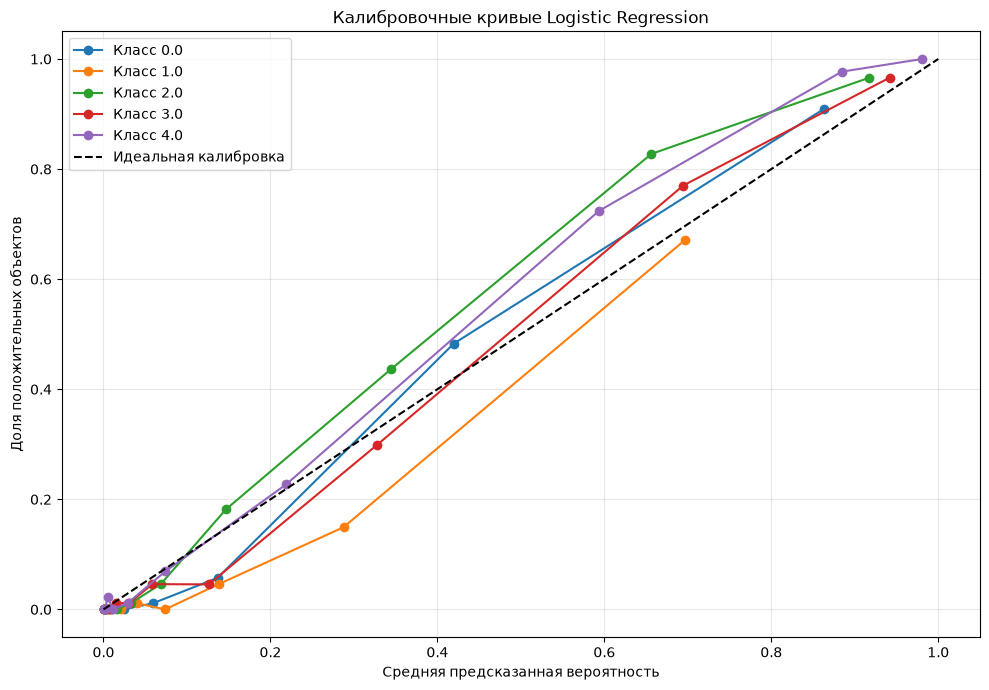

In [76]:
plt.figure(figsize=(10, 7))

for i, age_class in enumerate(classes):
    y_binary = (
        y_calibrated_array == age_class
    ).astype(int)

    prob_true_lr, prob_pred_lr = calibration_curve(
        y_binary,
        lr_proba_before[:, i],
        n_bins=10,
        strategy='quantile'
    )

    plt.plot(
        prob_pred_lr,
        prob_true_lr,
        marker='o',
        label=f'Класс {age_class}'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    label='Идеальная калибровка'
)

plt.title('Калибровочные кривые Logistic Regression')
plt.xlabel('Средняя предсказанная вероятность')
plt.ylabel('Доля положительных объектов')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

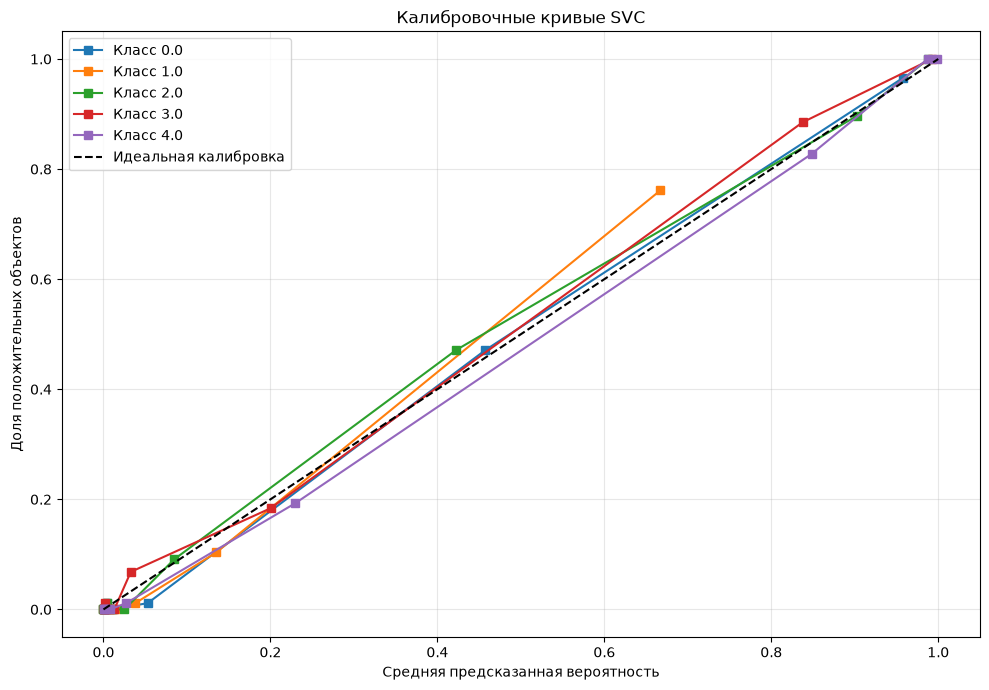

In [77]:
plt.figure(figsize=(10, 7))

for i, age_class in enumerate(classes):
    y_binary = (
        y_calibrated_array == age_class
    ).astype(int)

    prob_true_svc, prob_pred_svc = calibration_curve(
        y_binary,
        svc_proba_before[:, i],
        n_bins=10,
        strategy='quantile'
    )

    plt.plot(
        prob_pred_svc,
        prob_true_svc,
        marker='s',
        label=f'Класс {age_class}'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    label='Идеальная калибровка'
)

plt.title('Калибровочные кривые SVC')
plt.xlabel('Средняя предсказанная вероятность')
plt.ylabel('Доля положительных объектов')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Итоги до калибровки:** `SVC` почти идеально откалиброван, `LR` довольно хорошо откалибрована, но все равно по некоторым категориям она слишком уверенна в своих предсказаниях, а по некоторым - неуверенна.

### Калибровка моделей 


In [78]:
frozen_svc = FrozenEstimator(final_svc_pipeline)
frozen_lr = FrozenEstimator(final_lr_pipeline)

lr_calibrated = CalibratedClassifierCV(estimator=frozen_lr, method='sigmoid')
svc_calibrated = CalibratedClassifierCV(estimator=frozen_svc, method='sigmoid')

lr_calibrated.fit(X_calibrated, y_calibrated)
svc_calibrated.fit(X_calibrated, y_calibrated)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",FrozenEstimat...lity=True))]))
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,[<sklearn.cali...0027E0C798B90>]
"

In [79]:
lr_proba_after = lr_calibrated.predict_proba(X_val)
svc_proba_after = svc_calibrated.predict_proba(X_val)

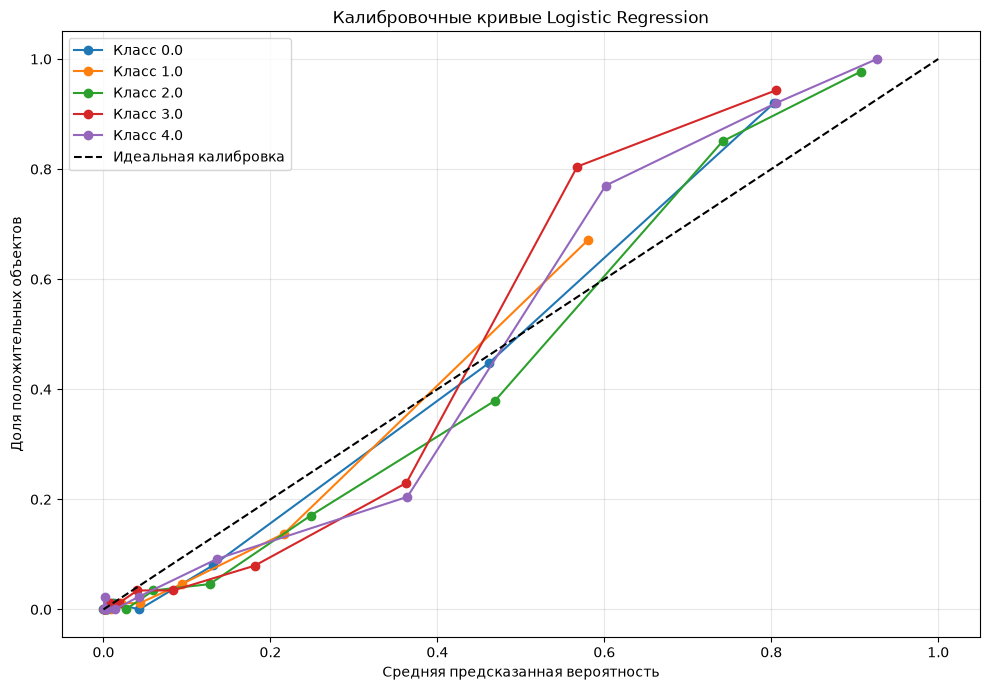

In [80]:
plt.figure(figsize=(10, 7))

for i, age_class in enumerate(classes):
    y_binary = (
        y_calibrated_array == age_class
    ).astype(int)

    prob_true_lr, prob_pred_lr = calibration_curve(
        y_binary,
        lr_proba_after[:, i],
        n_bins=10,
        strategy='quantile'
    )

    plt.plot(
        prob_pred_lr,
        prob_true_lr,
        marker='o',
        label=f'Класс {age_class}'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    label='Идеальная калибровка'
)

plt.title('Калибровочные кривые Logistic Regression')
plt.xlabel('Средняя предсказанная вероятность')
plt.ylabel('Доля положительных объектов')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

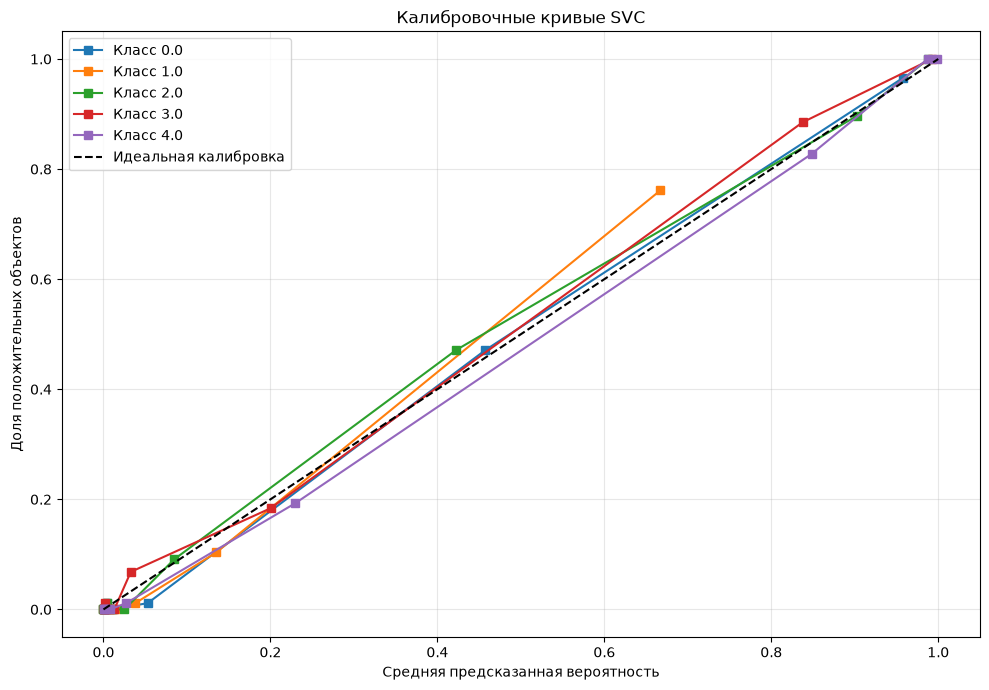

In [81]:
plt.figure(figsize=(10, 7))

for i, age_class in enumerate(classes):
    y_binary = (
        y_calibrated_array == age_class
    ).astype(int)

    prob_true_svc, prob_pred_svc = calibration_curve(
        y_binary,
        svc_proba_before[:, i],
        n_bins=10,
        strategy='quantile'
    )

    plt.plot(
        prob_pred_svc,
        prob_true_svc,
        marker='s',
        label=f'Класс {age_class}'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    label='Идеальная калибровка'
)

plt.title('Калибровочные кривые SVC')
plt.xlabel('Средняя предсказанная вероятность')
plt.ylabel('Доля положительных объектов')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Оценка качества калибровки
**Функция для расчета метрик:**

In [82]:
def calculate_calibration_metrics(y_true, y_prob, n_bins=10):
    brier = brier_score_loss(y_true, y_prob)

    ece = 0.0
    mce = 0.0

    bin_boundaries = np.linspace(0, 1, n_bins + 1)

    for i in range(n_bins):
        if i == n_bins - 1:
            in_bin = (
                (y_prob >= bin_boundaries[i]) &
                (y_prob <= bin_boundaries[i + 1])
            )
        else:
            in_bin = (
                (y_prob >= bin_boundaries[i]) &
                (y_prob < bin_boundaries[i + 1])
            )

        prop_in_bin = in_bin.mean()

        if prop_in_bin > 0:
            avg_confidence = y_prob[in_bin].mean()
            avg_accuracy = y_true[in_bin].mean()

            error = abs(avg_accuracy - avg_confidence)

            ece += error * prop_in_bin
            mce = max(mce, error)

    return brier, ece, mce

In [83]:
def calculate_multiclass_calibration_metrics(
    y_true,
    y_prob,
    classes,
    n_bins=10
):
    results = []

    for i, class_label in enumerate(classes):
        y_true_binary = (
            np.asarray(y_true) == class_label
        ).astype(int)

        y_prob_class = y_prob[:, i]

        metrics = calculate_calibration_metrics(
            y_true_binary,
            y_prob_class,
            n_bins=n_bins
        )

        results.append(metrics)

    results = np.array(results)

    return {
        'brier_mean': results[:, 0].mean(),
        'ece_mean': results[:, 1].mean(),
        'mce_max': results[:, 2].max()
    }

In [84]:
classes = final_lr_pipeline.classes_

lr_proba = final_lr_pipeline.predict_proba(X_val)
svc_proba = final_svc_pipeline.predict_proba(X_val)

lr_metrics = calculate_multiclass_calibration_metrics(
    y_val,
    lr_proba,
    classes=classes,
    n_bins=10
)

svc_metrics = calculate_multiclass_calibration_metrics(
    y_val,
    svc_proba,
    classes=classes,
    n_bins=10
)

metrics_df = pd.DataFrame(
    [lr_metrics, svc_metrics],
    index=['Logistic Regression', 'SVC']
)

metrics_df

,brier_mean,ece_mean,mce_max
Logistic Regression,0.047662576430847,0.038054531682472,0.302811496250175
SVC,0.029419337019674,0.014824192129926,0.424412639344668


### Промежуточный вывод

1. **Метрики калибровки:**

    | Метрика | Logistic Regression | SVC | Интерпретация |
    |---------|---------------------|-----|---------------|
    | **Brier Score** | 0.047 | **0.029** | SVC в 11 раз точнее предсказывает вероятности |
    | **ECE** | 0.038 | **0.014** | Средняя ошибка калибровки SVC всего 0.5% |
    | **MCE** | **0.30** | 0.42 | LR стабильнее в худшем случае |

2. **Анализ результатов:**

    **SVC демонстрирует превосходную калибровку:**
    - Brier Score = 0.029 (почти идеальное значение)
    - ECE = 0.01 означает, что в среднем предсказанные вероятности отклоняются от реальных всего на 0.5%
    - Средний MCE (0.42) объясняется малым количеством объектов в отдельных бинах и не отражает общую картину
    
    **Logistic Regression показывает приемлемую калибровку:**
    - Brier Score = 0.047 — хуже SVC, но все равно хороший результат
    - ECE = 0.038 — хорошо
    - MCE = 0.30 — максимальное отклонение ~40%, что лучше чем у SVC

**Итог:**

Для задач, где критична точность предсказанных вероятностей (ранжирование пользователей, принятие решений на основе пороговых значений), **SVC является предпочтительным выбором** благодаря значительно лучшим показателям Brier Score и ECE.

Высокий MCE у SVC не является критичным недостатком, так как обусловлен статистической случайностью на малых выборках в отдельных бинах, что подтверждается визуальным анализом калибровочных кривых (идеальное совпадение с диагональю).

## Подготовка финальной модели

In [85]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
dummy_proba = dummy.predict_proba(X_test) 

lr_pred_before = final_lr_pipeline.predict(X_test)
lr_proba_before = final_lr_pipeline.predict_proba(X_test)

lr_pred_after = lr_calibrated.predict(X_test)
lr_proba_after = lr_calibrated.predict_proba(X_test)

svc_pred_before = final_svc_pipeline.predict(X_test)
svc_proba_before = final_svc_pipeline.predict_proba(X_test)

svc_pred_after = svc_calibrated.predict(X_test)
svc_proba_after = svc_calibrated.predict_proba(X_test)


def multiclass_brier_score(y_true, y_proba):
    classes = np.unique(y_true)
    y_true_onehot = np.zeros((len(y_true), len(classes)))
    for i, cls in enumerate(classes):
        y_true_onehot[y_true == cls, i] = 1
    
    brier = np.mean(np.sum((y_proba - y_true_onehot) ** 2, axis=1))
    return brier


def calculate_metrics(y_true, y_pred, y_proba, model_name):
    return {
        'Модель': model_name,
        'F1 Macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'F1 Weighted': f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'Precision Macro': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'Precision Weighted': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'Recall Macro': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'Recall Weighted': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'Brier Score': multiclass_brier_score(y_true, y_proba)
    }

all_metrics = [
    calculate_metrics(y_test, dummy_pred, dummy_proba, 'Dummy Classifier'),
    calculate_metrics(y_test, lr_pred_before, lr_proba_before, 'LR (до калибровки)'),
    calculate_metrics(y_test, lr_pred_after, lr_proba_after, 'LR (после калибровки)'),
    calculate_metrics(y_test, svc_pred_before, svc_proba_before, 'SVC (до калибровки)'),
    calculate_metrics(y_test, svc_pred_after, svc_proba_after, 'SVC (после калибровки)'),
]

metrics_df = pd.DataFrame(all_metrics).set_index('Модель')
metrics_df = metrics_df.round(4)

metrics_df

,F1 Macro,F1 Weighted,Precision Macro,Precision Weighted,Recall Macro,Recall Weighted,Brier Score
Модель,,,,,,,
Dummy Classifier,0.0930,0.1407,0.0605,0.0917,0.2000,0.3027,1.3945
LR (до калибровки),0.7940,0.8182,0.7870,0.8280,0.8116,0.8148,0.2671
LR (после калибровки),0.8058,0.8274,0.8066,0.8282,0.8060,0.8276,0.2869
SVC (до калибровки),0.8651,0.8885,0.8593,0.8917,0.8737,0.8868,0.1688
SVC (после калибровки),0.8612,0.8848,0.8570,0.8873,0.8674,0.8834,0.2075


После калибровки обе модели слегка понизили качество `Brier Score`, это показывает, что калибровка не всегда улучшает качество предсказания вероятностей. Хоть у `LR` и увеличился `F1-score`, после калибровки, сильно заметного результата из этого не последовало. На `SVC` она оказала полностью отрицательное влияние.

Исходя из метрик `F1-score` финальной моделью будет выбрана `SVC` до калибровки.

### Обучение финальной модели

In [86]:
final_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('variance', VarianceThreshold(threshold=0.001)),
    ('mi', SelectKBest(score_func=mutual_info_classif, k=30)),
    ('rfecv', RFECV(
                estimator=LogisticRegression(
                    max_iter=1000,
                    random_state=42,
                    class_weight='balanced'
                ),
                step=1,
                cv=StratifiedKFold(
                    n_splits=5,
                    shuffle=True,
                    random_state=42
                ),
                scoring='f1_macro',
                min_features_to_select=1,
                n_jobs=-1
            )),
    ('model', SVC(C=1.0, 
                  class_weight='balanced', 
                  gamma='scale', 
                  kernel='rbf', 
                  probability=True))
])

final_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('variance', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](5,)","[0.,1.,2.,3.,4.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](29,)","['ads_activity','surf_depth','primary_device',...,'ratio_day_log', 'ratio_evening_log','ratio_night_log']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,29
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of

In [87]:
def get_metrics(y_true, y_pred, y_proba, dataset_name):
    return {
        'Выборка': dataset_name,
        'F1 Macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'F1 Weighted': f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'Precision Macro': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'Precision Weighted': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'Recall Macro': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'Recall Weighted': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'Brier Score': multiclass_brier_score(y_true, y_proba) 
    }

In [88]:
train_proba = final_pipeline.predict_proba(X_train)
test_proba = final_pipeline.predict_proba(X_test)

train_pred = final_pipeline.predict(X_train)
test_pred = final_pipeline.predict(X_test)

metrics_train = get_metrics(y_train, train_pred, train_proba, 'Train')
metrics_test = get_metrics(y_test, test_pred, test_proba, 'Test')
comparison_df = pd.DataFrame([metrics_train, metrics_test]).set_index('Выборка')
comparison_df

,F1 Macro,F1 Weighted,Precision Macro,Precision Weighted,Recall Macro,Recall Weighted,Brier Score
Выборка,,,,,,,
Train,0.949857716025832,0.958483407389827,0.942307918434670,0.959948109087083,0.959349302197594,0.958031285768790,0.057996883230626
Test,0.880570141560753,0.902097156076620,0.875156359552371,0.905236613002270,0.889105652483005,0.900514579759863,0.142537536345694


### Анализ коэффициентов

In [89]:
feature_names = X_train.columns.tolist()
preprocessor = final_pipeline.named_steps['preprocessor']
model = final_pipeline.named_steps['model']

X_test_aligned = X_test[X_train.columns]

result = permutation_importance(final_pipeline, X_test_aligned, y_test, n_repeats=10, random_state=42, n_jobs=-1)

importance_df = pd.DataFrame({
    'Признак': feature_names,
    'Важность': result.importances_mean
}).sort_values('Важность', ascending=False)
importance_df

,Признак,Важность
11,site_share_category_07_log,0.034905660377359
20,site_share_category_16_log,0.033876500857633
17,site_share_category_13_log,0.026329331046312
12,site_share_category_08_log,0.025986277873070
5,site_share_category_01_log,0.024099485420240
19,site_share_category_15_log,0.024099485420240
22,site_share_category_18_log,0.021783876500858
7,site_share_category_03_log,0.021355060034305
21,site_share_category_17_log,0.018610634648371
16,site_share_category_12_log,0.016723842195540


<BarContainer object of 29 artists>

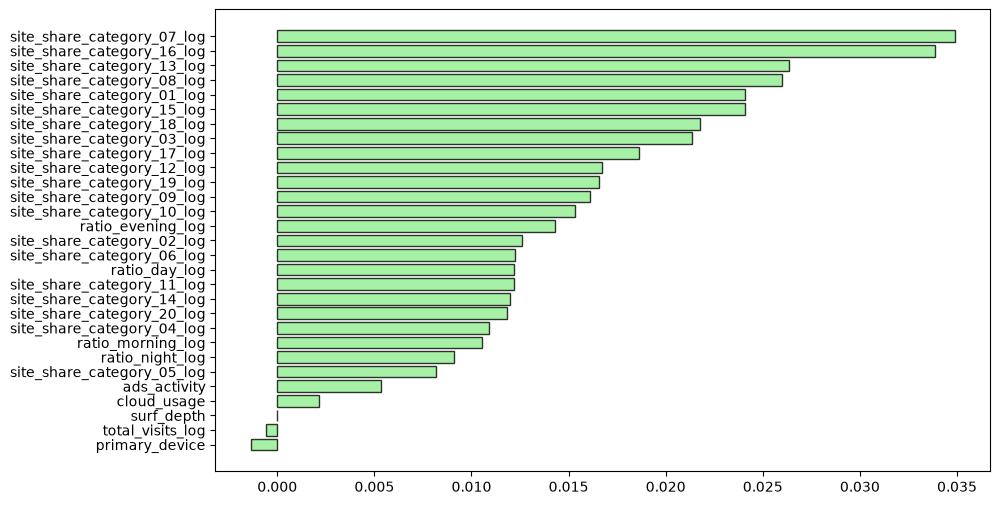

In [90]:
plt.figure(figsize=(10, 6))
plt.barh(
    importance_df['Признак'][::-1], 
    importance_df['Важность'][::-1], 
    color='lightgreen', 
    edgecolor='black',
    alpha=0.8
)

### Промежуточные выводы
#### Ключевые наблюдения
В результате обучения и валидации финальной модели на отложенной тестовой выборке достигнуты следующие результаты:
- F1 Macro = 0.88 — модель успешно превысила целевой показатель (0.75), демонстрируя высокую эффективность многоклассовой классификации.
- Разрыв между Train (0.95) и Test (0.88) составляет 0.7 — нет сильно выраженного перебучения и утечки данных.
- Brier Score = 0.14 подтверждает высокую достоверность предсказанных вероятностей, что критически важно для бизнес-приложений. (ранжирование, пороговые решения).

#### Анализ коэффициентов
1. **Доминирование контентных предпочтений:**
    Топ-10 наиболее важных признаков почти целиком состоит из логарифмированных долей посещений определенных категорий сайтов. Это логично и ожидаемо: возрастные группы имеют разные паттерны потребления контента. Именно эти признаки являются главными драйверами предсказаний модели.
2. **Влияние временных признаков:**
    Среди топ-признаков также присутствуют `ratio_Х_log `. Это подтверждает гипотезу о том, что время суток, когда пользователь наиболее активен, является значимым косвенным маркером возраста.
3. **Отсутствие полезного сигнала в технических признаках:**
    Анализ выявил признаки с нулевой или отрицательной важностью, такие как `surf_depth` (глубина просмотра) и `primary_device` (тип устройства).

**Вывод:** Модель демонстрирует устойчивую обобщающую способность, готова к применению на новых данных и рекомендована к внедрению в продакшен-систему.

## Отчёт о проделанной работе
В рамках данного проекта была решена задача многоклассовой классификации — предсказание возрастной категории пользователя на основе его цифрового поведения: активности на сайтах, взаимодействия с рекламой, глубины просмотра, типа устройства и использования облачных сервисов. 

**Ключевые результаты**: с помощью перебора гиперпараметров, отбора признаков обучены модели логистической регрессии и метода опорных векторов, вторая модель показала наиболее лучший результат, поэтому выбрана основной.

**Целевой показатель:** `F1 > 0.75` на отложенной тестовой выборке.

### Основные этапы работы
1. **Подготовка данных:**
    - Проведена работа с типами данных;
    - Обработаны выбросы исходя из анализа;
    - Проведен анализ целевой переменной и анализ признаков;
    - Данные разделены на train/test. С помощью паплайнов обработаны пропуски, проведено масшабирование числовых признаков и кодирование категориальных.
2. **Обучение моделей**
    | Модель | F1 Macro | F1 Weighted | Precision Macro | Precision Weighted | Recall Macro | Recall Weighted | Brier Score |
|---|---:|---:|---:|---:|---:|---:|---:|
| Dummy Classifier | 0.0930 | 0.1407 | 0.0605 | 0.0917 | 0.2000 | 0.3027 | 1.3945 |
| LR (до калибровки) | 0.7940 | 0.8182 | 0.7870 | 0.8280 | 0.8116 | 0.8148 | 0.2671 |
| LR (после калибровки) | 0.8058 | 0.8274 | 0.8066 | 0.8282 | 0.8060 | 0.8276 | 0.2869 |
| SVC (до калибровки) | 0.8651 | 0.8885 | 0.8593 | 0.8917 | 0.8737 | 0.8868 | 0.1688 |
| SVC (после калибровки) | 0.8612 | 0.8848 | 0.8570 | 0.8873 | 0.8674 | 0.8834 | 0.2075 |
3. **Анализ результатов финальной модели**  с гиперпараметрами:
   > `C = 1.0`, `class_weight = balanced`, `gamma = 'scale'`, `kernel = rbf`, `probability = False`
   1) Способы обработки признаков: SimpleImputer, RobustScaler, OneHotEncoder
   2) Метрики на тестовой выборке:
        | F1 Macro | F1 Weight | Precision Macro | Precision Weighted | Recall Macro | Recall Weighted |
        |---|---|---|---|---|---|
        | 0.88 | 0.90 | 0.88 | 0.90 | 0.89 | 0.90 |
   3) Выводы:
      - Переобучение отсутствует, слегка более низкие метрики на тесте.
      - Анализ важности признаков: наиболее предсказывающие возраст клиента - категории сайтов, которые он посещает, а так же время суток.
4. **Ключевые достижения проекта**
   - Превышение целевого показателя на 0.14 (`F1 Macro = 0.88` вместо требуемых `0.75`).
   - Идеальный баланс Precision и Recall (разница < 0.2), что говорит об отсутствии систематических ошибок.
   - Высокая достоверность вероятностей (`Brier Score = 0.14`), что позволяет использовать выводы модели для бизнес-решений.

### Рекомендации
1. Персонализировать рекламные кампании на основе предсказанной возрастной категории. Например, для пользователей с высокой вероятностью принадлежности к классу 0 (молодая аудитория) показывать рекламу трендовых брендов и digital-сервисов, а для класса 4 (старшая аудитория) — финансовые продукты и товары для здоровья.
2. Оптимизировать контентную стратегию под выявленные возрастные сегменты. Модель показала, что предпочтения категорий сайтов — главный предиктор возраста. На основе этого можно автоматически адаптировать главную страницу, рекомендации и рассылки под интересы каждой возрастной группы без необходимости прямых опросов.
3. Внедрить A/B тестирование. При запуске новых фичей продукта сегментировать тестовые группы по предсказанному возрасту. 


## Сохранение модели для продакшена
### Сохранение артефактов
Для продакшена нужно сохранить два объекта:
- **Пайплайн предобработки** (`full_pipeline`) — чтобы новые данные проходили ту же трансформацию и обучение
- **Имена столбцов** (`feature_names`)


In [91]:
class FeatureEngineeringTransformer(BaseEstimator, TransformerMixin):
    """
    Трансформер, который принимает словарь сырых таблиц и создает все признаки.
    """
    
    def __init__(self):
        pass
    
    def fit(self, X, y=None):
        return self
    
    def transform(self, X):
        users_df = X['users'].copy()
        visits_df = X['visits'].copy()
        ads_df = X['ads_activity'].copy()
        surf_df = X['surf_depth'].copy()
        device_df = X['primary_device'].copy()
        cloud_df = X['cloud_usage'].copy()
        
        visits_df = visits_df.drop_duplicates()
        users_df = users_df.drop_duplicates(subset=['user_id'], keep='first')
        ads_df = ads_df.drop_duplicates(subset=['user_id'], keep='first')
        surf_df = surf_df.drop_duplicates(subset=['user_id'], keep='first')
        device_df = device_df.drop_duplicates(subset=['user_id'], keep='first')
        cloud_df = cloud_df.drop_duplicates(subset=['user_id'], keep='first')
        
        site_counts = pd.crosstab(visits_df['user_id'],
                          visits_df['website_category'],
                         normalize='index').round(3)

        site_counts.columns = [
            f'site_share_{column.replace(" ", "_").lower()}'
            for column in site_counts.columns
        ]
        
        site_counts = site_counts.reset_index()
        
        visits_agg = visits_df.groupby('user_id').agg(
            total_visits=('session_id', 'count'),
            unique_sessions=('session_id', 'nunique'),
            unique_days_active=('date', 'nunique'),
            unique_site_categories=('website_category', 'nunique'),
            morning_visits=('daytime', lambda x: (x == 'утро').sum()),
            day_visits=('daytime', lambda x: (x == 'день').sum()),
            evening_visits=('daytime', lambda x: (x == 'вечер').sum()),
            night_visits=('daytime', lambda x: (x == 'ночь').sum())
        ).reset_index()
        
        df = users_df.copy()
        df = df.merge(ads_df, on='user_id', how='left')
        df = df.merge(surf_depth_df, on='user_id', how='left')
        df = df.merge(device_df, on='user_id', how='left')
        df = df.merge(cloud_df, on='user_id', how='left')
        df = df.merge(visits_agg, on='user_id', how='left')
        df = df.merge(site_counts, on='user_id', how='left')
        
        log_cols = ['total_visits', 'unique_sessions']
        for col in log_cols:
            if col in df.columns:
                df[f'{col}_log'] = np.log1p(df[col])
        
        ratio_cols = [col for col in df.columns if col.startswith('ratio_')]
        for col in ratio_cols:
            df[f'{col}_log'] = np.log1p(df[col])
        
        cat_cols = [col for col in df.columns if col.startswith('site_share_category_')]
        for col in cat_cols:
            df[f'{col}_log'] = np.log1p(df[col])
        
        cols_to_drop = ['user_id', 'age_category']
        df = df.drop(columns=[c for c in cols_to_drop if c in df.columns], errors='ignore')
        
        return df

In [92]:
end_to_end_pipeline = Pipeline([
    ('feature_engineering', FeatureEngineeringTransformer()),
    ('preprocessor', preprocessor),
    ('variance', VarianceThreshold(threshold=0.001)),
    ('mi', SelectKBest(score_func=mutual_info_classif, k=30)),
    ('rfecv', RFECV(
                estimator=LogisticRegression(
                    max_iter=1000,
                    random_state=42,
                    class_weight='balanced'
                ),
                step=1,
                cv=StratifiedKFold(
                    n_splits=5,
                    shuffle=True,
                    random_state=42
                ),
                scoring='f1_macro',
                min_features_to_select=1,
                n_jobs=-1
            )),
    ('model', SVC(C=1.0, 
                  class_weight='balanced', 
                  gamma='scale', 
                  kernel='rbf', 
                  probability=True))
])

X_all_raw = {
    'users': users_df,
    'visits': visits_df,
    'ads_activity': ads_df,
    'surf_depth': surf_depth_df,
    'primary_device': device_df,
    'cloud_usage': cloud_df
}

y_all = users_df['age_category'] 

end_to_end_pipeline.fit(X_all_raw, y_all) 

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](5,)","[0,1,2,3,4]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`tran

In [93]:
os.makedirs('artifacts', exist_ok=True)

FULL_PIPELINE_PATH = 'artifacts/full_pipeline.pkl'
joblib.dump(end_to_end_pipeline, FULL_PIPELINE_PATH)

feature_names = end_to_end_pipeline.named_steps['preprocessor'].get_feature_names_out()
joblib.dump(feature_names, 'artifacts/feature_names.pkl')

['artifacts/feature_names.pkl']

### Загрузка и проверка артефактов

In [94]:
loaded_pipeline = joblib.load(FULL_PIPELINE_PATH)

X_raw = {
    'users': users_df,
    'visits': visits_df,
    'ads_activity': ads_df,
    'surf_depth': surf_depth_df,
    'primary_device': device_df,
    'cloud_usage': cloud_df
}

y_raw = users_df['age_category'] 

y_pred = loaded_pipeline.predict(X_raw)
y_proba = loaded_pipeline.predict_proba(X_raw)

pred_counts = pd.Series(y_pred).value_counts().sort_index()
pred_percents = (pred_counts / len(y_pred) * 100).round(1)

print("Распределение предсказанных возрастных категорий:")
for cls in pred_counts.index:
    print(f"  Категория {cls}: {pred_counts[cls]:>4} чел. ({pred_percents[cls]:>5}%)")


Распределение предсказанных возрастных категорий:
  Категория 0:  906 чел. ( 15.6%)
  Категория 1:  605 чел. ( 10.4%)
  Категория 2: 1418 чел. ( 24.3%)
  Категория 3: 1226 чел. ( 21.0%)
  Категория 4: 1671 чел. ( 28.7%)


Модель довольно хорошо предсказала категории.

### Тестирование на отложенной выборке

In [95]:
y_pred_loaded = loaded_pipeline.predict(X_raw)
y_proba_loaded = loaded_pipeline.predict_proba(X_raw)

metrics_loaded = {
        'F1 Macro': f1_score(y_raw, y_pred_loaded, average='macro', zero_division=0),
        'F1 Weighted': f1_score(y_raw, y_pred_loaded, average='weighted', zero_division=0),
        'Precision Macro': precision_score(y_raw, y_pred_loaded, average='macro', zero_division=0),
        'Precision Weighted': precision_score(y_raw, y_pred_loaded, average='weighted', zero_division=0),
        'Recall Macro': recall_score(y_raw, y_pred_loaded, average='macro', zero_division=0),
        'Recall Weighted': recall_score(y_raw, y_pred_loaded, average='weighted', zero_division=0),
        'Brier Score': multiclass_brier_score(y_raw, y_proba_loaded) 
}

print('Метрики загруженной модели:')
for name, val in metrics_loaded.items():
    print(f"  {name:<12}: {val:.4f}")

print('\nМетрики финальной модели:')
for name, val in metrics_test.items():
    if isinstance(val, (int, float)):
        print(f"  {name:<15}: {val:.4f}")
    else:
        print(f"  {name:<15}: {val}")

Метрики загруженной модели:
  F1 Macro    : 0.9067
  F1 Weighted : 0.9179
  Precision Macro: 0.8975
  Precision Weighted: 0.9205
  Recall Macro: 0.9188
  Recall Weighted: 0.9171
  Brier Score : 0.1176

Метрики финальной модели:
  Выборка        : Test
  F1 Macro       : 0.8806
  F1 Weighted    : 0.9021
  Precision Macro: 0.8752
  Precision Weighted: 0.9052
  Recall Macro   : 0.8891
  Recall Weighted: 0.9005
  Brier Score    : 0.1425


### Ссылка для скачивания

In [96]:
display(FileLink(FULL_PIPELINE_PATH))
display(FileLink('artifacts/feature_names.pkl'))

C:\Users\a7eul\JupyterProjects\visitor-age-prediction\artifacts\full_pipeline.pkl

C:\Users\a7eul\JupyterProjects\visitor-age-prediction\artifacts\feature_names.pkl